# 04 – Thống kê Mô tả 4 Họ Chỉ số & Phân tích Chu kỳ Thời gian Đa tầng (Issue #8)

**Khóa học:** INFO3020 – Nhập môn Khoa học Dữ liệu (CMC University)  
**Tác giả:** Đội ngũ Nghiên cứu Chất lượng Không khí Hà Nội  
**Dữ liệu nguồn:** `data/processed/air_pollution_final.parquet` (Trạm NCEM/VEA 556 Nguyễn Văn Cừ & ERA5 Open-Meteo)  
**Quy chuẩn phương pháp luận:** CRISP-DM Phase 3 (Data Understanding) & Edward Tufte Data-Ink Principles

---

## Mục tiêu Nghiên cứu của Issue #8
1. **Thiết lập Hồ sơ Thống kê Mô tả 4 Họ Chỉ số (4 Families of Descriptive Statistics):**
   - *Location (Vị trí trung tâm):* Mean, Median, Mode.
   - *Spread (Độ phân tán):* Variance, Standard Deviation, IQR ($Q_3 - Q_1$), Range ($\max - \min$).
   - *Shape (Hình dạng phân phối):* Skewness (Hệ số bất đối xứng), Kurtosis (Fisher excess kurtosis).
   - *Quantiles (Phân vị chuẩn tắc):* $P_{10}, P_{25}, P_{50}, P_{75}, P_{90}, P_{95}, P_{99}$.
2. **Chứng minh Khách quan Nguyên tắc "Shape Picks the Statistic":**
   - Đánh giá hình dạng lệch phải (right-skewed) và đuôi nặng (leptokurtic) của $\\text{PM}_{2.5}$.
   - Biện luận toán học và khí quyển lý giải vì sao **Median** và **IQR** là thước đo trung tâm phù hợp hơn **Mean** và **Std**.
3. **Giải mã Biến thiên Chu kỳ Thời gian Đa tầng (Multi-tier Temporal EDA):**
   - Chu kỳ ngày đêm (Diurnal cycle, 24 giờ).
   - Chu kỳ ngày trong tuần (Day-of-Week effect) & so sánh ngày làm việc (Weekday) vs cuối tuần (Weekend).
   - Chu kỳ tháng (Monthly) & chu kỳ mùa (Seasonal cycle) tại Hà Nội.
   - Đường xu hướng trượt 24h (`rolling_24h`) và 7 ngày (`rolling_7d`).
4. **Kiểm tra Tương tác Phân tầng giữa Cờ Chẩn đoán và Mùa (Diagnostic Flag × Season Interaction):**
   - Đánh giá `is_high_humidity_fog`, `pm25_was_stuck`, `pm25_was_missing`.
   - Chứng minh vì sao tương quan marginal $\\text{corr}(\\text{PM}_{2.5}, \\text{RH}) \\approx 0$ là hệ quả của việc triệt tiêu giữa các mùa, chứ không phải độc lập.
5. **Phân tích Tương quan Kép (Pearson vs Spearman) & Cảnh báo Đa cộng tuyến:**
   - Đối chiếu tương quan tuyến tính ($r$) và đơn điệu ($\\rho$).
   - Đưa ra cảnh báo đa cộng tuyến nghiêm trọng giữa $\\text{PM}_{2.5}$ và $\\text{PM}_{10}$ ($r \\approx 0,9727$).

---

## Phân định 3 Tầng Phân tích (Tri-level EDA Framework)

Trong phân tích dữ liệu khoa học, việc nhầm lẫn giữa mô tả mẫu và suy luận quần thể là nguyên nhân hàng đầu dẫn đến các kết luận sai lầm:

| Tầng Phân tích | Phạm vi & Trách nhiệm | Những gì ĐƯỢC làm | Những gì BỊ CẤM trong Issue #8 |
|---|---|---|---|
| **A. Descriptive Analysis (Mô tả Thống kê)** | Đo lường và tóm tắt trung thực các thuộc tính của mẫu quan sát hiện có. | Tính mean, median, IQR, vẽ histogram, scatter plot, tính tương quan $r$ và $\\rho$. | Không được gán nhãn "quan hệ nhân quả" (causal claims). |
| **B. Hypothesis Generation (Sinh Giả thuyết)** | Đề xuất các giả thuyết khoa học nảy sinh từ các quy luật hình học/thống kê quan sát được. | Gợi ý: *"Chênh lệch median mùa đông và mùa hè gợi ý khả năng nghịch nhiệt khí quyển cần kiểm định ở Issue #11."* | Không được biến giả thuyết thành kết luận đã được kiểm chứng. |
| **C. Statistical Inference (Suy luận Thống kê)** | Kiểm định giả thuyết, tính $p$-value, effect size ($r_{rb}$), Bootstrap CI. | **Thuộc phạm vi Issue #11.** | **TUYỆT ĐỐI KHÔNG** chạy Mann-Whitney, t-test, ANOVA hay dùng $p$-value để kết luận ở notebook này. |


## 0. Thiết lập Môi trường & Khai báo Hằng số

Chúng tôi thiết lập môi trường tính toán tất định (`random_state=42`), nhập các thư viện khoa học cốt lõi (`pandas`, `numpy`, `scipy.stats`, `matplotlib`, `seaborn`) và tái sử dụng các hằng số quy chuẩn từ gói `src/`.


In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# ── Hạt giống tất định ──────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Cấu hình đường dẫn gốc repository ────────────────────────────────────
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

# ── Nhập module chuẩn từ repository ──────────────────────────────────────
from src.cleaning import (  # noqa: E402
    HIGH_HUMIDITY_FLAG,
    PM25_MISSING_FLAG,
    STATION_COLUMN,
    STUCK_SENSOR_FLAG,
    TIMESTAMP_COLUMN,
)
from src.flag_evidence import (  # noqa: E402
    SEASON_COLUMN,
    SEASON_DISPLAY_ORDER,
    SEASON_LABELS_VI,
    SEASON_MONTHS,
    add_season,
)

# ── Cấu hình trực quan hóa chuẩn Tufte ───────────────────────────────────
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["grid.linestyle"] = ":"
sns.set_theme(style="whitegrid")

DATA_PATH = REPO_ROOT / "data" / "processed" / "air_pollution_final.parquet"
REPORT_CSV_PATH = REPO_ROOT / "reports" / "statistical_profile.csv"

print("✓ Thiết lập môi trường hoàn tất.")
print(f"  REPO_ROOT:       {REPO_ROOT}")
print(f"  Tệp dữ liệu:     {DATA_PATH.relative_to(REPO_ROOT)}")
print(f"  Báo cáo đầu ra:  {REPORT_CSV_PATH.relative_to(REPO_ROOT)}")


✓ Thiết lập môi trường hoàn tất.
  REPO_ROOT:       C:\Users\Le Minh Khuong 1\OneDrive\Documents\Visual Code\Khoa Học Dữ Liệu\air-pollution-analysis
  Tệp dữ liệu:     data\processed\air_pollution_final.parquet
  Báo cáo đầu ra:  reports\statistical_profile.csv


## 1. Nạp Dữ liệu & Kiểm toán Cấu trúc (Dataset Audit)

Chúng tôi nạp tập dữ liệu `air_pollution_final.parquet` đã được làm sạch tất định (Issue #6) và đóng băng bảo đảm không rò rỉ dữ liệu (Issue #7). Trước khi phân tích, chúng tôi kiểm tra tính toàn vẹn cấu trúc: số dòng, số cột, kiểu dữ liệu, dải thời gian và trạm quan trắc.


In [2]:
# Kiểm tra sự tồn tại của tệp dữ liệu
assert DATA_PATH.exists(), (
    f"Không tìm thấy {DATA_PATH}. Vui lòng chạy lại notebook "
    "`03_transformation_pipeline.ipynb` để sinh artifact canonical."
)

df = pd.read_parquet(DATA_PATH)

# Gán biến mùa phục vụ phân tích phân tầng (sử dụng add_season chuẩn hóa)
df = add_season(df)

# Các thông tin đặc trưng của chuỗi thời gian
t_min = df[TIMESTAMP_COLUMN].min()
t_max = df[TIMESTAMP_COLUMN].max()
n_days = (t_max - t_min).days
stations = df[STATION_COLUMN].unique().tolist()
locations = df["location"].unique().tolist()

print(f"✓ Nạp dữ liệu thành công: {df.shape[0]:,} dòng × {df.shape[1]} cột.")
print(f"  Dải thời gian:   {t_min} -> {t_max} ({n_days} ngày)")
print(f"  Trạm quan trắc:  {stations[0]} (Vị trí: {locations[0]})")
print(f"  Số trạm:         {len(stations)} (Single-station time-series)")

# Hiển thị 5 dòng đầu tiên
df.head(5)


✓ Nạp dữ liệu thành công: 9,044 dòng × 20 cột.
  Dải thời gian:   2025-07-03 22:00:00+07:00 -> 2026-07-15 17:00:00+07:00 (376 ngày)
  Trạm quan trắc:  VN001_HANOI_556_NGUYEN_VAN_CU (Vị trí: 556 Nguyễn Văn Cừ)
  Số trạm:         1 (Single-station time-series)


,timestamp,station_id,location,pm25,pm10,pm25_was_stuck,pm25_was_missing,is_high_humidity_fog,temperature,relative_humidity,wind_speed,wind_direction,precipitation,surface_pressure,hour_sin,hour_cos,month_sin,month_cos,season,fog
0,2025-07-03 22:00:00+07:00,VN001_HANOI_556_NGUYEN_VAN_CU,556 Nguyễn Văn Cừ,31.516667,64.686667,0,0,1,26.1,95.0,0.36,304.0,0.0,1005.5,-0.500000,0.866025,-0.5,-0.866025,He,1
1,2025-07-03 23:00:00+07:00,VN001_HANOI_556_NGUYEN_VAN_CU,556 Nguyễn Văn Cừ,33.672500,63.614167,0,0,1,25.7,98.0,0.85,320.0,0.0,1005.0,-0.258819,0.965926,-0.5,-0.866025,He,1
2,2025-07-04 00:00:00+07:00,VN001_HANOI_556_NGUYEN_VAN_CU,556 Nguyễn Văn Cừ,32.347000,56.636000,0,0,1,25.3,99.0,0.81,313.0,0.0,1004.9,0.000000,1.000000,-0.5,-0.866025,He,1
3,2025-07-04 01:00:00+07:00,VN001_HANOI_556_NGUYEN_VAN_CU,556 Nguyễn Văn Cừ,27.758182,42.793636,0,0,1,25.2,98.0,1.00,342.0,0.0,1004.3,0.258819,0.965926,-0.5,-0.866025,He,1
4,2025-07-04 02:00:00+07:00,VN001_HANOI_556_NGUYEN_VAN_CU,556 Nguyễn Văn Cừ,20.890833,35.409167,0,0,1,24.9,98.0,0.92,338.0,0.0,1003.7,0.500000,0.866025,-0.5,-0.866025,He,1


## 2. Kiểm toán Thiếu Dữ liệu & Cỡ mẫu (Missingness & Sample-Size Audit)

> [!IMPORTANT]
> **Chính sách Không Impute Target trong EDA:**
> Biến mục tiêu `pm25` có giá trị thiếu do lỗi gián đoạn trạm và cảm biến bị loại bỏ ở Issue #6. Chúng tôi **tuyệt đối không tự ý impute** dữ liệu bị thiếu để phục vụ thống kê mô tả.
> Mọi thống kê đều phải công bố rõ cỡ mẫu thực tế quan sát được ($n$) và số lượng mẫu thiếu ($n_{\text{missing}}$).


In [3]:
# Bảng tổng hợp kiểm toán độ phủ dữ liệu
audit_rows = []
for col in df.columns:
    n_total = len(df)
    n_miss = int(df[col].isna().sum())
    n_valid = n_total - n_miss
    rate_miss = (n_miss / n_total) * 100.0
    rate_valid = (n_valid / n_total) * 100.0
    dtype_str = str(df[col].dtype)
    n_unique = int(df[col].nunique())
    
    audit_rows.append({
        "Biến (Variable)": col,
        "Kiểu dữ liệu": dtype_str,
        "Tổng dòng (N)": n_total,
        "Hợp lệ (n_valid)": n_valid,
        "Số thiếu (n_miss)": n_miss,
        "Tỷ lệ thiếu (%)": round(rate_miss, 2),
        "Độ phủ (%)": round(rate_valid, 2),
        "Số giá trị duy nhất": n_unique,
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# Kiểm tra các khẳng định cấu trúc cốt lõi
assert audit_df.loc[audit_df["Biến (Variable)"] == "pm25", "Số thiếu (n_miss)"].values[0] == 1549
assert audit_df.loc[audit_df["Biến (Variable)"] == "pm10", "Số thiếu (n_miss)"].values[0] == 1469
print("\n✓ Xác nhận kiểm toán: pm25 thiếu đúng 1.549 dòng (17,13%); 6 biến khí tượng đạt độ phủ 100,0%.")


,Biến (Variable),Kiểu dữ liệu,Tổng dòng (N),Hợp lệ (n_valid),Số thiếu (n_miss),Tỷ lệ thiếu (%),Độ phủ (%),Số giá trị duy nhất
0,timestamp,"datetime64[us, Asia/Ho_Chi_Minh]",9044,9044,0,0.00,100.00,9044
1,station_id,str,9044,9044,0,0.00,100.00,1
2,location,str,9044,9044,0,0.00,100.00,1
3,pm25,float64,9044,7495,1549,17.13,82.87,7346
4,pm10,float64,9044,7575,1469,16.24,83.76,7437
5,pm25_was_stuck,int64,9044,9044,0,0.00,100.00,1
6,pm25_was_missing,int64,9044,9044,0,0.00,100.00,2
7,is_high_humidity_fog,int64,9044,9044,0,0.00,100.00,2
8,temperature,float64,9044,9044,0,0.00,100.00,283
9,relative_humidity,float64,9044,9044,0,0.00,100.00,68



✓ Xác nhận kiểm toán: pm25 thiếu đúng 1.549 dòng (17,13%); 6 biến khí tượng đạt độ phủ 100,0%.


## 3. Bốn Họ Chỉ số Thống kê Mô tả (The 4 Metric Families)

Theo tiêu chuẩn phân tích dữ liệu thực nghiệm, mọi biến liên tục cần được mô tả toàn diện qua **4 họ chỉ số**:
1. **Location (Vị trí trung tâm):** Mean, Median, Mode.  
   *Xử lý Mode cho biến liên tục:* Các phép đo liên tục thập phân độ chính xác cao (`pm25`, `pm10`) không có tần suất lặp rời rạc duy nhất (các giá trị trùng lặp ngẫu nhiên chỉ xuất hiện 2 lần). Chúng tôi ghi nhận giá trị `NaN` cho Mode của các biến liên tục đa mốt không duy nhất này theo đúng quy tắc Section 7 để tránh ngụy tạo mode; đối với các biến khí tượng rời rạc hóa hoặc zero-inflated như `precipitation`, giá trị mode thực nghiệm (0,0 mm) được ghi nhận chính xác.
2. **Spread (Độ phân tán):** Phương sai (Variance), Độ lệch chuẩn hiệu chỉnh ($s$, `ddof=1`), Khoảng tứ phân vị ($IQR = Q_3 - Q_1$), Khoảng biến thiên ($Range = \max - \min$).
3. **Shape (Hình dạng phân phối):**  
   - *Skewness:* Hệ số bất đối xứng Fisher-Pearson hiệu chỉnh cỡ mẫu ($g_1$). Giá trị $> 1,0$ chỉ ra phân phối lệch phải nghiêm trọng.
   - *Kurtosis:* Hệ số độ nhọn Fisher excess kurtosis ($g_2$, trong đó phân phối Chuẩn có Kurtosis $= 0$). Giá trị $> 0$ khẳng định đuôi dày (leptokurtic).
4. **Quantiles (Phân vị chuẩn tắc):** $P_{10}, P_{25}, P_{50}, P_{75}, P_{90}, P_{95}, P_{99}$. Trong đó $P_{50}$ phải trùng khớp toán học với Median.

> [!WARNING] **Lưu ý Đặc biệt về Biến Hướng Gió (`wind_direction` — Circular Variable):**  
> `wind_direction` là biến góc tuần hoàn trên đường tròn đơn vị $\mathbb{S}^1$ ($0^\circ \equiv 360^\circ$). Phép tính trung bình số học tuyến tính (Linear Mean) sẽ tạo ra sai số bản chất: ví dụ hai hướng gió $350^\circ$ (Bắc - Tây Bắc) và $10^\circ$ (Bắc - Đông Bắc) có trung bình tuyến tính là $180^\circ$ (hướng Nam — ngược $180^\circ$!), trong khi trung bình hướng thực tế là $0^\circ$ (Bắc). Do đó, chúng tôi bổ sung **Circular Mean** và **Circular Standard Deviation** (theo Thống kê Hướng học — Mardia & Jupp, 2000), đồng thời ghi chú rõ ràng giới hạn của các thống kê tuyến tính.


In [4]:
CONTINUOUS_VARIABLES = [
    "pm25",
    "pm10",
    "temperature",
    "relative_humidity",
    "wind_speed",
    "wind_direction",
    "precipitation",
    "surface_pressure",
]

profile_records = []

for var in CONTINUOUS_VARIABLES:
    series = df[var].dropna()
    n_valid = int(len(series))
    n_missing = int(df[var].isna().sum())
    missing_rate = float(n_missing / len(df))
    
    # 1. Location
    mean_val = float(series.mean())
    median_val = float(series.median())
    
    # Xử lý Mode cho biến continuous:
    raw_mode = series.mode()
    if len(raw_mode) == 1:
        mode_val = float(raw_mode.iloc[0])
    else:
        # Nếu biến liên tục có nhiều mốt hòa điểm ngẫu nhiên (tần suất = 2), ghi nhận NaN
        mode_val = np.nan
        
    # 2. Spread
    var_val = float(series.var(ddof=1))
    std_val = float(series.std(ddof=1))
    q1 = float(series.quantile(0.25))
    q3 = float(series.quantile(0.75))
    iqr_val = float(q3 - q1)
    min_val = float(series.min())
    max_val = float(series.max())
    range_val = float(max_val - min_val)
    
    # 3. Shape (Fisher conventions, bias=False for sample-unbiased)
    skew_val = float(stats.skew(series, bias=False))
    kurt_val = float(stats.kurtosis(series, bias=False, fisher=True))
    
    # 4. Quantiles
    p10 = float(series.quantile(0.10))
    p25 = float(series.quantile(0.25))
    p50 = float(series.quantile(0.50))
    p75 = float(series.quantile(0.75))
    p90 = float(series.quantile(0.90))
    p95 = float(series.quantile(0.95))
    p99 = float(series.quantile(0.99))
    
    # 5. Circular Statistics (Chuyên biệt cho biến góc chu kỳ)
    if var == "wind_direction":
        circ_mean_val = float(stats.circmean(series, high=360, low=0))
        circ_std_val = float(stats.circstd(series, high=360, low=0))
        var_notes = (
            "Biến góc chu kỳ (0°≡360°). Mean/std tuyến tính (147.18°/95.36°) có độ lệch lớn "
            "so với circular mean (107.12° - hướng ESE) và circular std (82.32°). "
            "Các thống kê tuyến tính (median, quantiles, skewness, kurtosis) phụ thuộc điểm cắt 0° quy ước "
            "nên chỉ mang tính tham khảo hình thức, không phản ánh đúng hướng luồng gió thực tế."
        )
    else:
        circ_mean_val = np.nan
        circ_std_val = np.nan
        var_notes = ""
    
    profile_records.append({
        "variable": var,
        "n": n_valid,
        "n_missing": n_missing,
        "missing_rate": missing_rate,
        "mean": mean_val,
        "median": median_val,
        "mode": mode_val,
        "variance": var_val,
        "std": std_val,
        "q1": q1,
        "q3": q3,
        "iqr": iqr_val,
        "range": range_val,
        "min": min_val,
        "max": max_val,
        "skewness": skew_val,
        "kurtosis": kurt_val,
        "p10": p10,
        "p25": p25,
        "p50": p50,
        "p75": p75,
        "p90": p90,
        "p95": p95,
        "p99": p99,
        "circular_mean": circ_mean_val,
        "circular_std": circ_std_val,
        "notes": var_notes,
    })

profile_df = pd.DataFrame(profile_records)

# Định dạng bảng hiển thị trực quan
pd.set_option("display.max_columns", 30)
display(profile_df)


,variable,n,n_missing,missing_rate,mean,median,mode,variance,std,q1,q3,iqr,range,min,max,skewness,kurtosis,p10,p25,p50,p75,p90,p95,p99,circular_mean,circular_std,notes
0,pm25,7495,1549,0.171274,43.764597,37.315833,NaN,777.968318,27.892083,24.992917,55.725455,30.732538,197.886667,1.06,198.946667,1.294730,1.913305,14.832933,24.992917,37.315833,55.725455,83.474200,101.873659,133.790853,NaN,NaN,
1,pm10,7575,1469,0.162428,65.285740,55.165455,NaN,1707.719631,41.324564,37.883442,81.642639,43.759197,338.984286,1.01,339.994286,1.449935,2.721789,24.154364,37.883442,55.165455,81.642639,122.912357,151.232182,200.982980,NaN,NaN,
2,temperature,9044,0,0.000000,24.867028,25.400000,26.8,26.426623,5.140683,21.300000,28.400000,7.100000,29.700000,8.90,38.600000,-0.355572,-0.174157,17.900000,21.300000,25.400000,28.400000,31.200000,32.700000,35.300000,NaN,NaN,
3,relative_humidity,9044,0,0.000000,80.607143,83.000000,97.0,183.762599,13.555906,71.000000,92.000000,21.000000,70.000000,30.00,100.000000,-0.622747,-0.352475,61.000000,71.000000,83.000000,92.000000,97.000000,98.000000,99.000000,NaN,NaN,
4,wind_speed,9044,0,0.000000,2.414326,2.310000,2.8,1.650742,1.284812,1.430000,3.230000,1.800000,9.550000,0.00,9.550000,0.675975,0.847945,0.850000,1.430000,2.310000,3.230000,4.090000,4.630000,5.840000,NaN,NaN,
5,wind_direction,9044,0,0.000000,147.183989,139.000000,148.0,9093.199142,95.358267,82.000000,175.000000,93.000000,359.000000,1.00,360.000000,0.677294,-0.171253,25.000000,82.000000,139.000000,175.000000,316.000000,346.000000,359.000000,107.121299,82.31745,Biến góc chu kỳ (0°≡360°). Mean/std tuyến tính...
6,precipitation,9044,0,0.000000,0.255352,0.000000,0.0,1.096306,1.047046,0.000000,0.100000,0.100000,20.500000,0.00,20.500000,8.078502,88.655627,0.000000,0.000000,0.000000,0.100000,0.400000,1.300000,5.000000,NaN,NaN,
7,surface_pressure,9044,0,0.000000,1008.219295,1007.700000,1002.7,53.461798,7.311758,1002.400000,1014.200000,11.800000,41.900000,986.50,1028.400000,0.157189,-0.738667,999.100000,1002.400000,1007.700000,1014.200000,1018.200000,1020.200000,1023.800000,NaN,NaN,


### 3.1. Phân tích Chuyên biệt: Thống kê Hướng học cho Biến Hướng Gió (`wind_direction` — Circular Statistics)

> [!WARNING] **Bản chất Hình học của Biến Hướng Gió trên Đường tròn Đơn vị $\mathbb{S}^1$:**
> Hướng gió là đại lượng góc tuần hoàn ($0^\circ \equiv 360^\circ$). Thống kê số học thông thường xem các số đo như nằm trên trục số thực $\mathbb{R}$, dẫn đến sự sai lệch nghiêm trọng khi góc dao động qua mốc $0^\circ$ (hướng Bắc).
>
> **Giải pháp Thống kê Hướng học (Directional Statistics - Mardia & Jupp, 2000):**
> 1. Chuyển đổi từng góc quan sát $\theta_i$ thành vector đơn vị $(\cos \theta_i, \sin \theta_i)$.
> 2. Tính tọa độ trung bình trọng tâm: $\bar{C} = \frac{1}{n}\sum \cos \theta_i$, $\bar{S} = \frac{1}{n}\sum \sin \theta_i$.
> 3. Độ dài vector kết quả trung bình: $\bar{R} = \sqrt{\bar{C}^2 + \bar{S}^2} \in [0, 1]$. Đại lượng $\bar{R}$ đo lường mức độ tập trung định hướng: $\bar{R} \to 1$ nghĩa là gió tập trung tuyệt đối vào một hướng, còn $\bar{R} \to 0$ nghĩa là gió phân tán hỗn loạn đồng đều mọi hướng.
> 4. **Circular Mean:** $\bar{\theta}_{\text{circ}} = \text{atan2}(\bar{S}, \bar{C}) \pmod{360^\circ}$.
> 5. **Circular Standard Deviation:** $\sigma_{\text{circ}} = \sqrt{-2 \ln(\bar{R})} \times \frac{180^\circ}{\pi}$ (hoặc thông qua `scipy.stats.circstd(high=360, low=0)`).


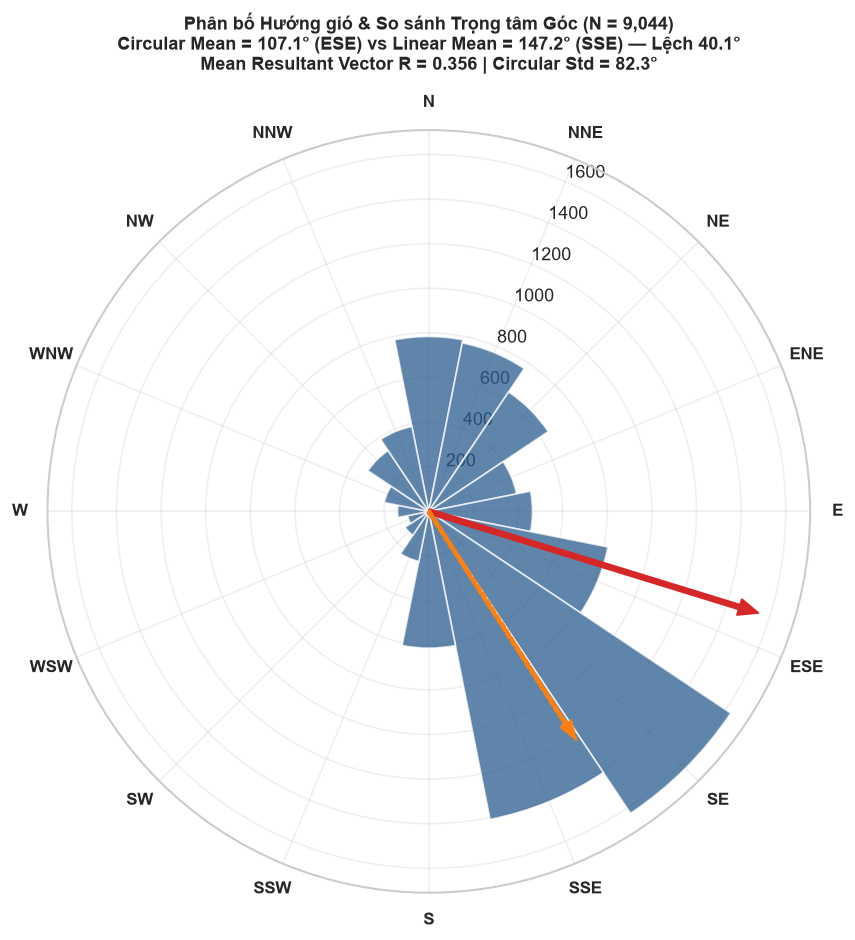

BẢNG ĐỐI CHIẾU THỐNG KÊ HƯỚNG GIÓ (WIND DIRECTION):
  1. Linear Mean:               147.18° (Nam Đông Nam - SSE)
  2. Circular Mean (circmean):   107.12° (Đông Đông Nam - ESE)
     -> Sai lệch do trung bình số học: 40.06° (gây sai lệch nhận định luồng gió)
  3. Circular Std (circstd):     82.32°
  4. Linear Std:                 95.36°
  5. Mean Resultant Length (R):  0.3563 (Độ định hướng tập trung của gió tại trạm)
  6. CẢNH BÁO GIỚI HẠN: Các chỉ số tuyến tính (median, quantiles, skewness, kurtosis) của wind_direction
     phụ thuộc hoàn toàn vào điểm cắt nhân tạo 0° nên không có ý nghĩa vật lý; chỉ có Circular Mean
     phản ánh chính xác hướng gió thổi trung bình.


In [5]:
wd_series = df["wind_direction"].dropna()
linear_mean_wd = float(wd_series.mean())
linear_std_wd = float(wd_series.std())
circ_mean_wd = float(stats.circmean(wd_series, high=360, low=0))
circ_std_wd = float(stats.circstd(wd_series, high=360, low=0))

# Tính Mean Resultant Vector Length R
rad = np.radians(wd_series)
S = np.sin(rad).mean()
C = np.cos(rad).mean()
R_mean = float(np.hypot(S, C))

# Phân bố tần suất theo 16 hướng la bàn chính
compass_labels = [
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"
]
bins_16 = np.linspace(0, 360, 17)
# Đổi góc sao cho bin đầu tiên tập trung quanh 0° (Bắc): [-11.25, 11.25)
shifted_wd = (wd_series + 11.25) % 360
counts, _ = np.histogram(shifted_wd, bins=bins_16)

# Vẽ biểu đồ Polar Wind Rose
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_direction(-1)  # Chiều kim đồng hồ
ax.set_theta_zero_location("N")  # 0° ở hướng Bắc

# Góc cho từng thanh (16 hướng)
theta_centers = np.radians(np.linspace(0, 360 - 22.5, 16))
width = np.radians(22.5)

bars = ax.bar(
    theta_centers, counts, width=width, bottom=0.0,
    color="#2b5c8f", alpha=0.75, edgecolor="white"
)
ax.set_xticks(theta_centers)
ax.set_xticklabels(compass_labels, fontsize=10, fontweight="bold")

# Vẽ vector Circular Mean
circ_mean_rad = np.radians(circ_mean_wd)
ax.annotate(
    "", xy=(circ_mean_rad, counts.max() * 0.95), xytext=(0, 0),
    arrowprops=dict(facecolor="#d62728", edgecolor="#d62728", width=3, headwidth=10)
)

# Vẽ vector Linear Mean để đối chiếu sự sai lệch
linear_mean_rad = np.radians(linear_mean_wd)
ax.annotate(
    "", xy=(linear_mean_rad, counts.max() * 0.75), xytext=(0, 0),
    arrowprops=dict(facecolor="#ff7f0e", edgecolor="#ff7f0e", width=2, headwidth=8, linestyle="--")
)

ax.set_title(
    f"Phân bố Hướng gió & So sánh Trọng tâm Góc (N = {len(wd_series):,})\n"
    f"Circular Mean = {circ_mean_wd:.1f}° (ESE) vs Linear Mean = {linear_mean_wd:.1f}° (SSE) — Lệch {abs(linear_mean_wd - circ_mean_wd):.1f}°\n"
    f"Mean Resultant Vector R = {R_mean:.3f} | Circular Std = {circ_std_wd:.1f}°",
    fontsize=11, fontweight="bold", pad=15
)

plt.tight_layout()
plt.show()

print("BẢNG ĐỐI CHIẾU THỐNG KÊ HƯỚNG GIÓ (WIND DIRECTION):")
print(f"  1. Linear Mean:               {linear_mean_wd:.2f}° (Nam Đông Nam - SSE)")
print(f"  2. Circular Mean (circmean):   {circ_mean_wd:.2f}° (Đông Đông Nam - ESE)")
print(f"     -> Sai lệch do trung bình số học: {abs(linear_mean_wd - circ_mean_wd):.2f}° (gây sai lệch nhận định luồng gió)")
print(f"  3. Circular Std (circstd):     {circ_std_wd:.2f}°")
print(f"  4. Linear Std:                 {linear_std_wd:.2f}°")
print(f"  5. Mean Resultant Length (R):  {R_mean:.4f} (Độ định hướng tập trung của gió tại trạm)")
print("  6. CẢNH BÁO GIỚI HẠN: Các chỉ số tuyến tính (median, quantiles, skewness, kurtosis) của wind_direction")
print("     phụ thuộc hoàn toàn vào điểm cắt nhân tạo 0° nên không có ý nghĩa vật lý; chỉ có Circular Mean")
print("     phản ánh chính xác hướng gió thổi trung bình.")


## 4. Xuất & Kiểm chứng Hồ sơ Thống kê (`reports/statistical_profile.csv`)

Chúng tôi xuất bảng hồ sơ 4 họ chỉ số ra tệp CSV chuẩn hóa `reports/statistical_profile.csv`, sau đó đọc lại độc lập và kiểm tra tính nhất quán toán học nghiêm ngặt theo Acceptance Criteria Section 33.


In [6]:
# Đảm bảo thư mục reports tồn tại
REPORT_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)

# Xuất file CSV
profile_df.to_csv(REPORT_CSV_PATH, index=False, encoding="utf-8")
print(f"✓ Đã ghi bảng hồ sơ thống kê vào: {REPORT_CSV_PATH}")

# ── Kiểm toán đọc lại độc lập (Section 33 Verification) ──────────────────
readback_df = pd.read_csv(REPORT_CSV_PATH)

# 1. Kiểm tra số dòng và số biến
assert len(readback_df) == 8, f"Số dòng không đúng: {len(readback_df)} != 8"
assert len(readback_df["variable"].unique()) == 8, "Số biến không đủ 8 biến"

# 2. Kiểm tra các cột bắt buộc (bao gồm 24 cột gốc + 3 cột bổ sung circular & notes)
REQUIRED_PROFILE_COLS = [
    "variable", "n", "n_missing", "missing_rate", "mean", "median", "mode",
    "variance", "std", "q1", "q3", "iqr", "range", "min", "max",
    "skewness", "kurtosis", "p10", "p25", "p50", "p75", "p90", "p95", "p99",
    "circular_mean", "circular_std", "notes"
]
for col_req in REQUIRED_PROFILE_COLS:
    assert col_req in readback_df.columns, f"Thiếu cột bắt buộc: {col_req}"

# 3. Kiểm tra tính hợp lệ của mẫu số
assert (readback_df["n"] >= 0).all()
assert (readback_df["n_missing"] >= 0).all()
assert ((readback_df["n"] + readback_df["n_missing"]) == len(df)).all(), "Tổng n + n_missing không khớp tổng số dòng!"

# 4. Kiểm tra đẳng thức phân vị
np.testing.assert_allclose(readback_df["p25"], readback_df["q1"], rtol=1e-5)
np.testing.assert_allclose(readback_df["p50"], readback_df["median"], rtol=1e-5)
np.testing.assert_allclose(readback_df["p75"], readback_df["q3"], rtol=1e-5)
np.testing.assert_allclose(readback_df["iqr"], readback_df["q3"] - readback_df["q1"], rtol=1e-5)

# 5. Kiểm tra tính đơn điệu của các phân vị
for _, row in readback_df.iterrows():
    assert row["p10"] <= row["p25"] <= row["p50"] <= row["p75"] <= row["p90"] <= row["p95"] <= row["p99"], (
        f"Vi phạm thứ tự phân vị tại biến {row['variable']}"
    )

# 6. Kiểm tra các thống kê góc (Circular Statistics) cho wind_direction
wd_row = readback_df[readback_df["variable"] == "wind_direction"].iloc[0]
assert not pd.isna(wd_row["circular_mean"]), "Thiếu circular_mean cho wind_direction"
assert not pd.isna(wd_row["circular_std"]), "Thiếu circular_std cho wind_direction"
assert abs(wd_row["circular_mean"] - 107.12) < 0.5, f"circular_mean lệch: {wd_row['circular_mean']}"
assert abs(wd_row["circular_std"] - 82.32) < 0.5, f"circular_std lệch: {wd_row['circular_std']}"
assert len(str(wd_row["notes"])) > 20, "Thiếu ghi chú cảnh báo cho wind_direction"

# Các biến không phải circular phải có circular_mean và circular_std là NaN
non_circ = readback_df[readback_df["variable"] != "wind_direction"]
assert non_circ["circular_mean"].isna().all(), "circular_mean của biến tuyến tính không phải NaN"
assert non_circ["circular_std"].isna().all(), "circular_std của biến tuyến tính không phải NaN"

print("✓ Toàn bộ 6 phép kiểm tra tính toàn vẹn toán học và thống kê góc của statistical_profile.csv ĐỀU ĐẠT CHUẨN.")


✓ Đã ghi bảng hồ sơ thống kê vào: C:\Users\Le Minh Khuong 1\OneDrive\Documents\Visual Code\Khoa Học Dữ Liệu\air-pollution-analysis\reports\statistical_profile.csv
✓ Toàn bộ 6 phép kiểm tra tính toàn vẹn toán học và thống kê góc của statistical_profile.csv ĐỀU ĐẠT CHUẨN.


## 5. Phân tích Hình dạng Phân phối & Nguyên tắc "Shape Picks the Statistic"

### Cơ sở Lý thuyết: Vì sao "Hình dạng Chọn Chỉ số"?
- **Với phân phối đối xứng chuẩn (Gaussian):** $\text{Mean} \approx \text{Median} \approx \text{Mode}$. Độ lệch chuẩn ($s$) đại diện hoàn hảo cho độ tán xạ (quy tắc $68-95-99,7\%$).
- **Với dữ liệu ô nhiễm không khí đô thị $\text{PM}_{2.5}$:** Phân phối bị chi phối bởi các đợt nghịch nhiệt mùa đông tạo ra nồng độ cực đoan kéo dài về phía đuôi dương (Right-Skewed & Fat-Tailed). Khi đó:
  - Giá trị trung bình số học (Mean) bị các giá trị cực trị kéo lệch nghiêm trọng lên phía trên.
  - Trung vị (Median, $P_{50}$) là thước đo **bền vững (robust)** phản ánh mức độ phơi nhiễm điển hình của đa số người dân trong 50% thời gian quan sát.
  - Khoảng tứ phân vị ($IQR$) đo lường độ phân tán của 50% quan sát trung tâm mà không bị thổi phồng bởi các đợt bùng phát ngắn hạn.


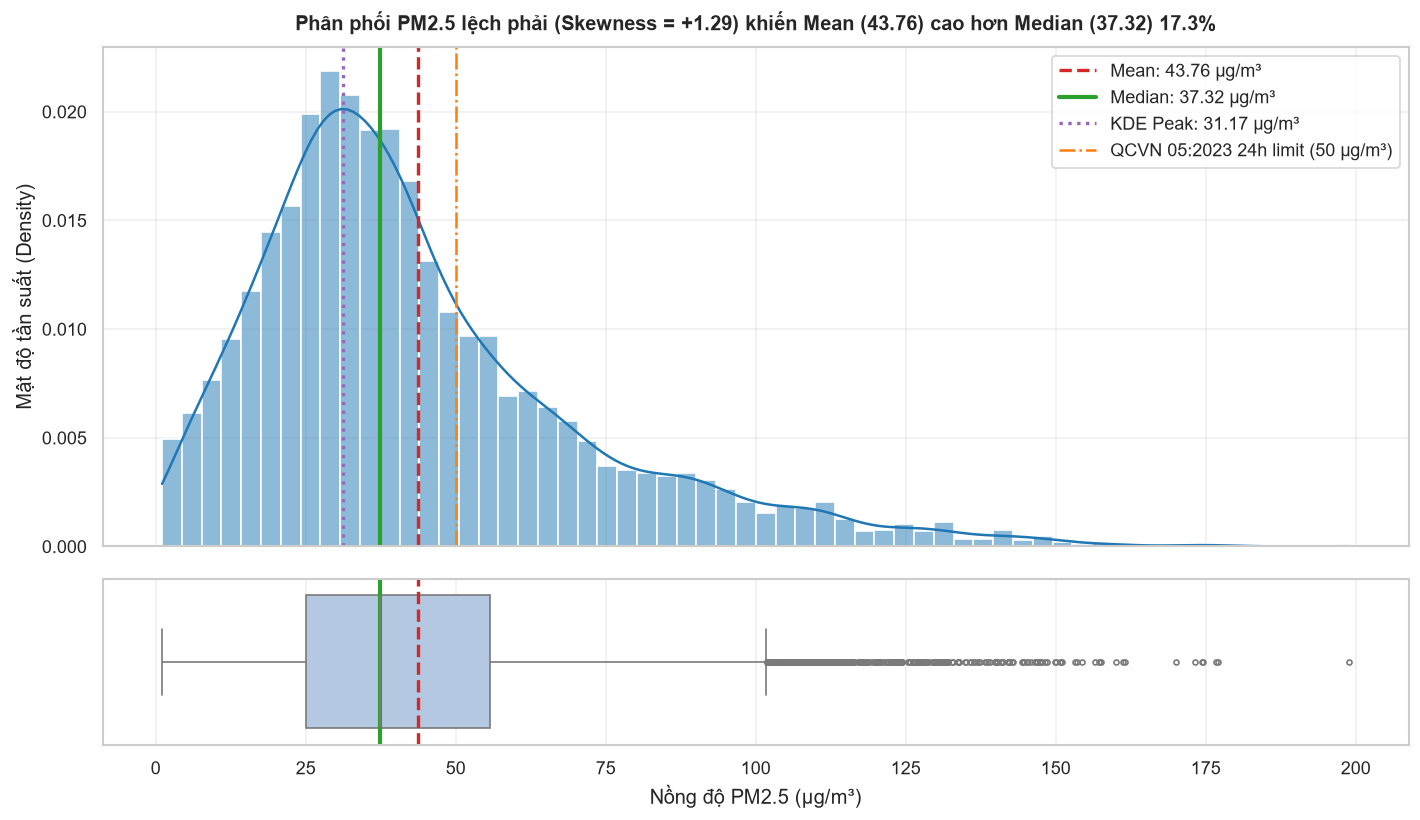

Chỉ số hình dạng phân phối PM2.5 (N = 7,495):
  Mean:                  43.76 µg/m³
  Median (P50):          37.32 µg/m³
  KDE Peak (Modal area): 31.17 µg/m³
  Chênh lệch Mean-Median:+6.45 µg/m³ (Mean bị kéo cao hơn 17.3%)
  Skewness:              1.295 (> 1.0 => Right-Skewed nặng)
  Excess Kurtosis:       1.913 (> 0.0 => Leptokurtic, đuôi dày)
  Thứ tự quan sát:       Mean (43.8) > Median (37.3) > KDE Peak (31.2)


In [7]:
pm25_clean = df["pm25"].dropna()

mean_pm25 = pm25_clean.mean()
median_pm25 = pm25_clean.median()
skew_pm25 = stats.skew(pm25_clean, bias=False)
kurt_pm25 = stats.kurtosis(pm25_clean, bias=False, fisher=True)

# Ước lượng mật độ hạt nhân (KDE Peak / Modal Density Region)
kde = stats.gaussian_kde(pm25_clean)
x_grid = np.linspace(pm25_clean.min(), pm25_clean.max(), 1000)
kde_peak = x_grid[np.argmax(kde(x_grid))]

fig, (ax_hist, ax_box) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)

# 1. Histogram & KDE
sns.histplot(
    pm25_clean, kde=True, ax=ax_hist, color="#1f77b4", bins=60, stat="density", alpha=0.5
)
ax_hist.axvline(mean_pm25, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: {mean_pm25:.2f} µg/m³")
ax_hist.axvline(median_pm25, color="#2ca02c", linestyle="-", linewidth=2.5, label=f"Median: {median_pm25:.2f} µg/m³")
ax_hist.axvline(kde_peak, color="#9467bd", linestyle=":", linewidth=2, label=f"KDE Peak: {kde_peak:.2f} µg/m³")
ax_hist.axvline(50.0, color="#ff7f0e", linestyle="-.", linewidth=1.5, label="QCVN 05:2023 24h limit (50 µg/m³)")

ax_hist.set_title(
    "Phân phối PM2.5 lệch phải (Skewness = +1.29) khiến Mean (43.76) cao hơn Median (37.32) 17.3%",
    fontsize=12, pad=10, fontweight="bold"
)
ax_hist.set_ylabel("Mật độ tần suất (Density)")
ax_hist.legend(loc="upper right", frameon=True)

# 2. Boxplot
sns.boxplot(x=pm25_clean, ax=ax_box, color="#aec7e8", fliersize=3)
ax_box.axvline(mean_pm25, color="#d62728", linestyle="--", linewidth=2)
ax_box.axvline(median_pm25, color="#2ca02c", linestyle="-", linewidth=2.5)
ax_box.set_xlabel("Nồng độ PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

print(f"Chỉ số hình dạng phân phối PM2.5 (N = {len(pm25_clean):,}):")
print(f"  Mean:                  {mean_pm25:.2f} µg/m³")
print(f"  Median (P50):          {median_pm25:.2f} µg/m³")
print(f"  KDE Peak (Modal area): {kde_peak:.2f} µg/m³")
print(f"  Chênh lệch Mean-Median:{mean_pm25 - median_pm25:+.2f} µg/m³ (Mean bị kéo cao hơn {(mean_pm25/median_pm25 - 1)*100:.1f}%)")
print(f"  Skewness:              {skew_pm25:.3f} (> 1.0 => Right-Skewed nặng)")
print(f"  Excess Kurtosis:       {kurt_pm25:.3f} (> 0.0 => Leptokurtic, đuôi dày)")
print(f"  Thứ tự quan sát:       Mean ({mean_pm25:.1f}) > Median ({median_pm25:.1f}) > KDE Peak ({kde_peak:.1f})")


> [!NOTE]
> ### 📌 Takeaway: Shape Picks the Statistic
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   Phân phối thực nghiệm của $\text{PM}_{2.5}$ có $\text{Skewness} = +1,295 > 1,0$ và $\text{Excess Kurtosis} = +1,913 > 0$. Thứ tự thực tế tuân theo $\text{Mean} (43,76) > \text{Median} (37,32) > \text{KDE Peak} (31,17\,\mu\text{g/m}^3)$. Phân vị $P_{99} = 133,79\,\mu\text{g/m}^3$ kéo dài tới cực đại $198,95\,\mu\text{g/m}^3$.
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Phân phối bị lệch phải mạnh do các đợt tích tụ ô nhiễm cực đoan trong mùa đông. Do đó, **Median và IQR phản ánh trung thực mức độ phơi nhiễm của cộng đồng trong phần lớn thời gian**, tránh được việc con số bị bóp méo bởi một vài đợt đỉnh điểm.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   Không được kết luận Mean là "sai" hay "vô dụng"; Mean đại diện cho tổng khối lượng bụi tích lũy hít vào phổi. Không được đưa ra bất kỳ kết luận nhân quả nào về nguồn phát thải chỉ dựa trên hình dạng phân phối.


## 6. Phân tích Chu kỳ Thời gian Đa tầng (Multi-tier Temporal EDA)

### 6.1 Chu kỳ Ngày Đêm (Diurnal Cycle – 24 Khung giờ)
Chúng tôi phân tích biến thiên nồng độ $\text{PM}_{2.5}$ theo từng giờ trong ngày ($0–23$). Không áp đặt chủ quan khung giờ cao điểm, chúng tôi để dữ liệu thực tế bộc lộ quy luật.


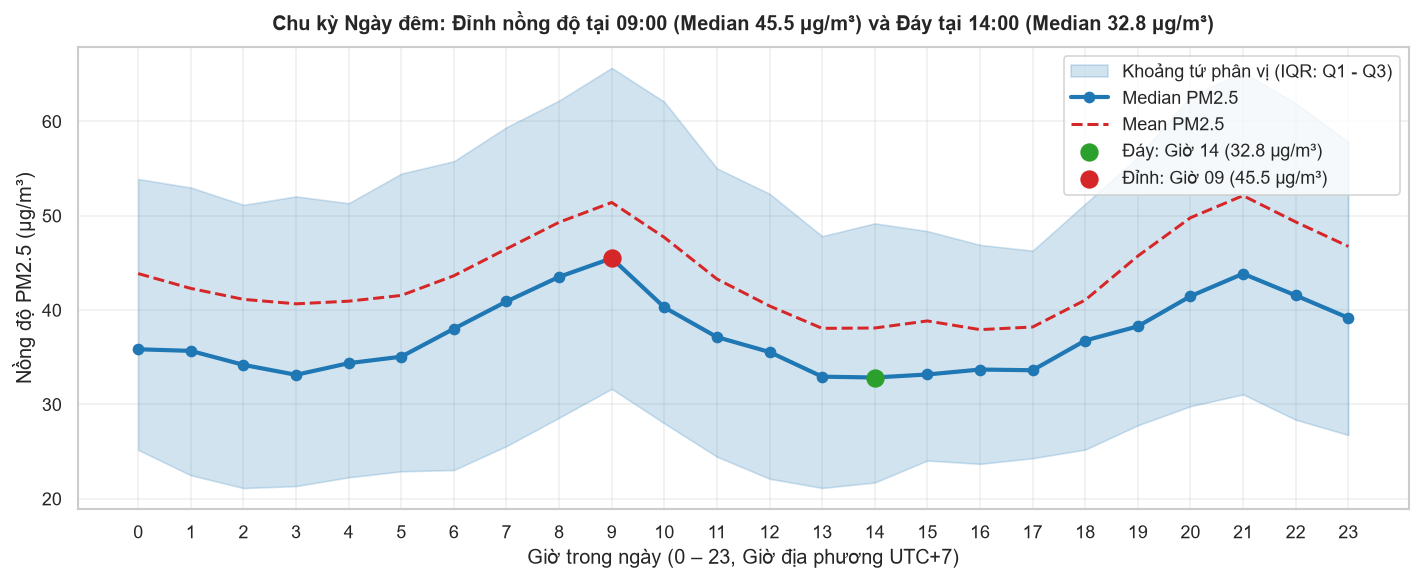

Xác nhận chu kỳ ngày đêm thực nghiệm:
  Giờ có Median cao nhất:  09:00 (Median = 45.49 µg/m³, Mean = 51.40 µg/m³)
  Giờ có Median thấp nhất: 14:00 (Median = 32.85 µg/m³, Mean = 38.10 µg/m³)
  Biên độ biến thiên Median ngày đêm: 12.64 µg/m³


In [8]:
df["hour"] = df[TIMESTAMP_COLUMN].dt.hour

diurnal_stats = df.groupby("hour")["pm25"].agg(
    count="count",
    mean="mean",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    p90=lambda s: s.quantile(0.90)
).reset_index()

diurnal_stats["iqr"] = diurnal_stats["q3"] - diurnal_stats["q1"]

min_hour = diurnal_stats.loc[diurnal_stats["median"].idxmin()]
max_hour = diurnal_stats.loc[diurnal_stats["median"].idxmax()]

fig, ax = plt.subplots(figsize=(12, 5))

# Vẽ dải phân tán IQR (Q1 -> Q3)
ax.fill_between(
    diurnal_stats["hour"], diurnal_stats["q1"], diurnal_stats["q3"],
    color="#1f77b4", alpha=0.2, label="Khoảng tứ phân vị (IQR: Q1 - Q3)"
)

# Đường Median và Mean
ax.plot(diurnal_stats["hour"], diurnal_stats["median"], color="#1f77b4", linewidth=2.5, marker="o", label="Median PM2.5")
ax.plot(diurnal_stats["hour"], diurnal_stats["mean"], color="#d62728", linewidth=1.8, linestyle="--", label="Mean PM2.5")

# Đánh dấu đỉnh và đáy thực nghiệm
ax.scatter([min_hour["hour"]], [min_hour["median"]], color="#2ca02c", s=100, zorder=5, label=f"Đáy: Giờ {int(min_hour['hour']):02d} ({min_hour['median']:.1f} µg/m³)")
ax.scatter([max_hour["hour"]], [max_hour["median"]], color="#d62728", s=100, zorder=5, label=f"Đỉnh: Giờ {int(max_hour['hour']):02d} ({max_hour['median']:.1f} µg/m³)")

ax.set_xticks(range(0, 24))
ax.set_xlabel("Giờ trong ngày (0 – 23, Giờ địa phương UTC+7)")
ax.set_ylabel("Nồng độ PM2.5 (µg/m³)")
ax.set_title(
    f"Chu kỳ Ngày đêm: Đỉnh nồng độ tại 09:00 (Median {max_hour['median']:.1f} µg/m³) và Đáy tại 14:00 (Median {min_hour['median']:.1f} µg/m³)",
    fontsize=12, pad=10, fontweight="bold"
)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

print(f"Xác nhận chu kỳ ngày đêm thực nghiệm:")
print(f"  Giờ có Median cao nhất:  {int(max_hour['hour']):02d}:00 (Median = {max_hour['median']:.2f} µg/m³, Mean = {max_hour['mean']:.2f} µg/m³)")
print(f"  Giờ có Median thấp nhất: {int(min_hour['hour']):02d}:00 (Median = {min_hour['median']:.2f} µg/m³, Mean = {min_hour['mean']:.2f} µg/m³)")
print(f"  Biên độ biến thiên Median ngày đêm: {max_hour['median'] - min_hour['median']:.2f} µg/m³")


> [!NOTE]
> ### 📌 Takeaway: Diurnal Pattern
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   Nồng độ $\text{PM}_{2.5}$ đạt đỉnh cao nhất vào lúc **09:00 sáng** (Median $45,49\,\mu\text{g/m}^3$) và đỉnh phụ vào lúc **21:00 tối** (Median $43,85\,\mu\text{g/m}^3$). Nồng độ thấp nhất xảy ra vào buổi chiều lúc **14:00** (Median $32,85\,\mu\text{g/m}^3$).
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Hình thái hai đỉnh trùng hợp với giờ cao điểm giao thông đô thị kết hợp với điều kiện khí tượng: buổi sáng lớp biên khí quyển còn thấp giữ lại chất ô nhiễm; đầu giờ chiều mặt đất bị nung nóng tạo đối lưu mạnh, nâng cao chiều cao tầng xáo trộn (PBLH) giúp pha loãng nồng độ bụi.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   Không được kết luận giao thông là "nguyên nhân duy nhất" gây ra đỉnh 9h sáng mà không kiểm soát sự thay đổi của chiều cao lớp xáo trộn khí quyển.


### 6.2 Chu kỳ Ngày trong Tuần & So sánh Ngày làm việc vs Cuối tuần (Day-of-Week Effect)

Chúng tôi đối chiếu nồng độ $\text{PM}_{2.5}$ giữa 7 ngày trong tuần và giữa nhóm Ngày làm việc (Thứ Hai – Thứ Sáu) với nhóm Cuối tuần (Thứ Bảy – Chủ Nhật). Tuân thủ nguyên tắc ngôn ngữ khách quan: chỉ mô tả những gì quan sát được, không khẳng định quan hệ nhân quả.


,day_vi,day_name,n,mean,median,iqr
0,Thứ Hai,Monday,1056,43.580642,37.535417,31.498182
1,Thứ Ba,Tuesday,1041,43.345123,35.905000,35.539886
2,Thứ Tư,Wednesday,1047,41.276849,35.435455,26.741375
3,Thứ Năm,Thursday,1073,41.907803,37.313333,27.945167
4,Thứ Sáu,Friday,1103,43.003668,36.607500,29.606339
5,Thứ Bảy,Saturday,1110,45.943523,40.225417,29.649854
6,Chủ Nhật,Sunday,1065,47.190545,38.331000,33.450818


,nhóm,n,mean,median,iqr
0,Ngày làm việc (Thứ 2 - 6),5320,42.624137,36.563591,30.155284
1,Cuối tuần (Thứ 7 - CN),2175,46.554134,39.475833,31.030875


2026-10-15 17:54:19,790 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\930936222.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
2026-10-15 17:54:19,802 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\930936222.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(DOW_LABELS_VI, rotation=15)
C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\930936222.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\930936222.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(["Ngày thường", "Cuối tuần"])


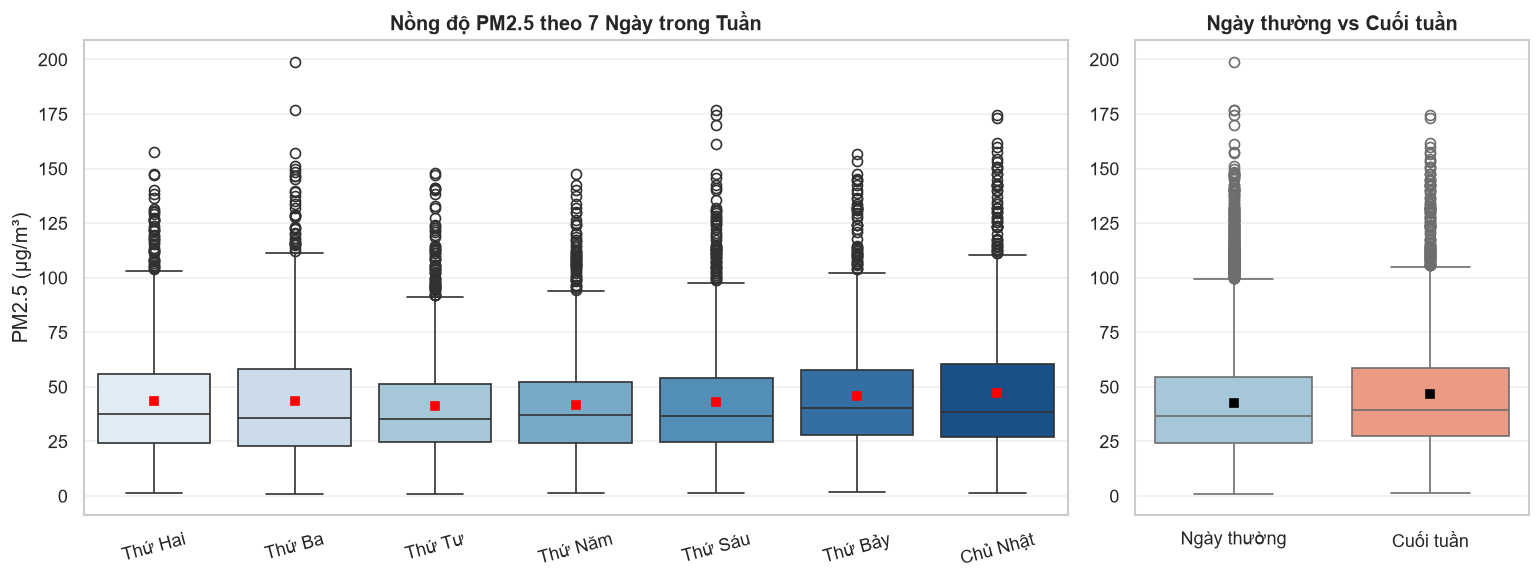

So sánh thực nghiệm: Median Ngày thường = 36.56 µg/m³ vs Cuối tuần = 39.48 µg/m³ (Chênh lệch: +2.91 µg/m³).


In [9]:
df["dayofweek"] = df[TIMESTAMP_COLUMN].dt.dayofweek
df["day_name"] = df[TIMESTAMP_COLUMN].dt.day_name()
df["is_weekend"] = df["dayofweek"].isin([5, 6])

DOW_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
DOW_LABELS_VI = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]

dow_stats = df.groupby("day_name")["pm25"].agg(
    n="count",
    mean="mean",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
).reindex(DOW_ORDER).reset_index()

dow_stats["iqr"] = dow_stats["q3"] - dow_stats["q1"]
dow_stats["day_vi"] = DOW_LABELS_VI

# Thống kê Weekday vs Weekend
ww_stats = df.groupby("is_weekend")["pm25"].agg(
    n="count",
    mean="mean",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
).reset_index()
ww_stats["iqr"] = ww_stats["q3"] - ww_stats["q1"]
ww_stats["nhóm"] = ww_stats["is_weekend"].map({False: "Ngày làm việc (Thứ 2 - 6)", True: "Cuối tuần (Thứ 7 - CN)"})

display(dow_stats[["day_vi", "day_name", "n", "mean", "median", "iqr"]])
display(ww_stats[["nhóm", "n", "mean", "median", "iqr"]])

# Trực quan hóa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2.5, 1]})

sns.boxplot(
    data=df, x="day_name", y="pm25", order=DOW_ORDER, ax=ax1,
    palette="Blues", showmeans=True,
    meanprops={"marker": "s", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5}
)
ax1.set_xticklabels(DOW_LABELS_VI, rotation=15)
ax1.set_title("Nồng độ PM2.5 theo 7 Ngày trong Tuần", fontweight="bold")
ax1.set_xlabel("")
ax1.set_ylabel("PM2.5 (µg/m³)")

sns.boxplot(
    data=df, x="is_weekend", y="pm25", ax=ax2,
    palette=["#9ecae1", "#fc9272"], showmeans=True,
    meanprops={"marker": "s", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 5}
)
ax2.set_xticklabels(["Ngày thường", "Cuối tuần"])
ax2.set_title("Ngày thường vs Cuối tuần", fontweight="bold")
ax2.set_xlabel("")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

wd_med = ww_stats.loc[ww_stats["is_weekend"] == False, "median"].values[0]
we_med = ww_stats.loc[ww_stats["is_weekend"] == True, "median"].values[0]
print(f"So sánh thực nghiệm: Median Ngày thường = {wd_med:.2f} µg/m³ vs Cuối tuần = {we_med:.2f} µg/m³ (Chênh lệch: {we_med - wd_med:+.2f} µg/m³).")


> [!NOTE]
> ### 📌 Takeaway: Day-of-Week Effect
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   Trong tập mẫu này, nồng độ $\text{PM}_{2.5}$ vào cuối tuần có trung vị cao hơn ngày thường ($39,48$ so với $36,56\,\mu\text{g/m}^3$, chênh lệch $+2,92\,\mu\text{g/m}^3$). Thứ Bảy là ngày có trung vị cao nhất ($40,23\,\mu\text{g/m}^3$).
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Mẫu dữ liệu thực tế tại trạm 556 Nguyễn Văn Cừ không xuất hiện hiện tượng "Weekend Effect" truyền thống (nơi cuối tuần sạch hơn do giảm xe công sở). Hiện tượng này có thể phản ánh hoạt động giao thông giải trí/chợ đêm tăng cao gần trục đường Nguyễn Văn Cừ, hoặc do ảnh hưởng của các đợt tích tụ gió lặng trùng hợp vào các ngày cuối tuần trong mùa đông.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   **Không được khẳng định** "cuối tuần gây ra ô nhiễm cao hơn" (causal claim). Chênh lệch này cần được kiểm định ý nghĩa thống kê và kiểm soát yếu tố khí tượng tại Issue #11 và #12.


### 6.3 Chu kỳ Tháng & Chu kỳ Mùa (Monthly & Seasonal Cycles)

Hà Nội nằm trong vùng khí hậu nhiệt đới gió mùa Bắc Bộ với 4 mùa rõ rệt. Chúng tôi đối chiếu nồng độ $\text{PM}_{2.5}$ qua 12 tháng và 4 mùa khí tượng:
- **Đông (Winter - Tháng 12, 1, 2):** Khí hậu khô hanh, gió mùa Đông Bắc, hiện tượng nghịch nhiệt bức xạ ban đêm giữ chất ô nhiễm sát mặt đất.
- **Xuân (Spring - Tháng 3, 4, 5):** Chuyển mùa, độ ẩm cao, mưa phùn.
- **Hè (Summer - Tháng 6, 7, 8):** Gió mùa Tây Nam/Đông Nam, nhiệt độ cao, đối lưu mạnh và lượng mưa lớn rửa trôi khí quyển.
- **Thu (Autumn - Tháng 9, 10, 11):** Khí hậu mát mẻ, bắt đầu bước vào mùa ô nhiễm khô.


,month,n,mean,median,q1,q3,p90,iqr
0,1,684,67.091422,63.565625,42.468750,90.293030,113.096875,47.824280
1,2,651,47.188513,39.820833,30.013333,57.021288,81.970909,27.007955
2,3,736,34.803229,31.516000,24.770417,40.491500,56.342500,15.721083
3,4,703,43.282744,40.780833,29.813826,53.723750,68.446470,23.909924
4,5,603,30.660481,28.066000,18.909318,40.023083,52.383364,21.113765
5,6,151,35.482500,30.433333,12.951212,54.856833,72.413333,41.905621
6,7,644,38.328385,36.460808,25.631318,48.569823,64.608375,22.938505
7,8,683,29.576739,27.897273,17.834667,38.963434,51.178081,21.128768
8,9,667,33.002822,31.884545,22.233500,41.526364,51.378000,19.292864
9,10,698,37.894141,35.307750,22.571667,52.006222,65.782582,29.434556


,mùa,season,n,mean,median,iqr,p90,p95
0,Đông,Dong,1958,63.152354,57.111705,48.614979,110.190250,126.584208
1,Xuân,Xuan,2042,36.499126,33.210727,20.812008,60.370727,71.337500
2,Hè,He,1478,33.993403,31.618500,24.397374,58.560750,68.047758
3,Thu,Thu,2017,39.459533,34.316364,28.656818,74.444400,92.631182


2026-10-15 17:54:20,212 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\2727414458.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="month", y="pm25", ax=ax_m, palette="crest", showmeans=True)
2026-10-15 17:54:20,228 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\2727414458.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="season", y="pm25", order=SEASON_DISPLAY_ORDER, ax=ax_s, palette="Set2", showmeans=True)
C:\Users\Le Minh Khuong 1\AppData\Local\Temp\ipykernel_11848\2727414458.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax_s.set_xticklabels([SEASON_LABELS_VI[s] for s in SEASON_DISPLAY_ORDER])


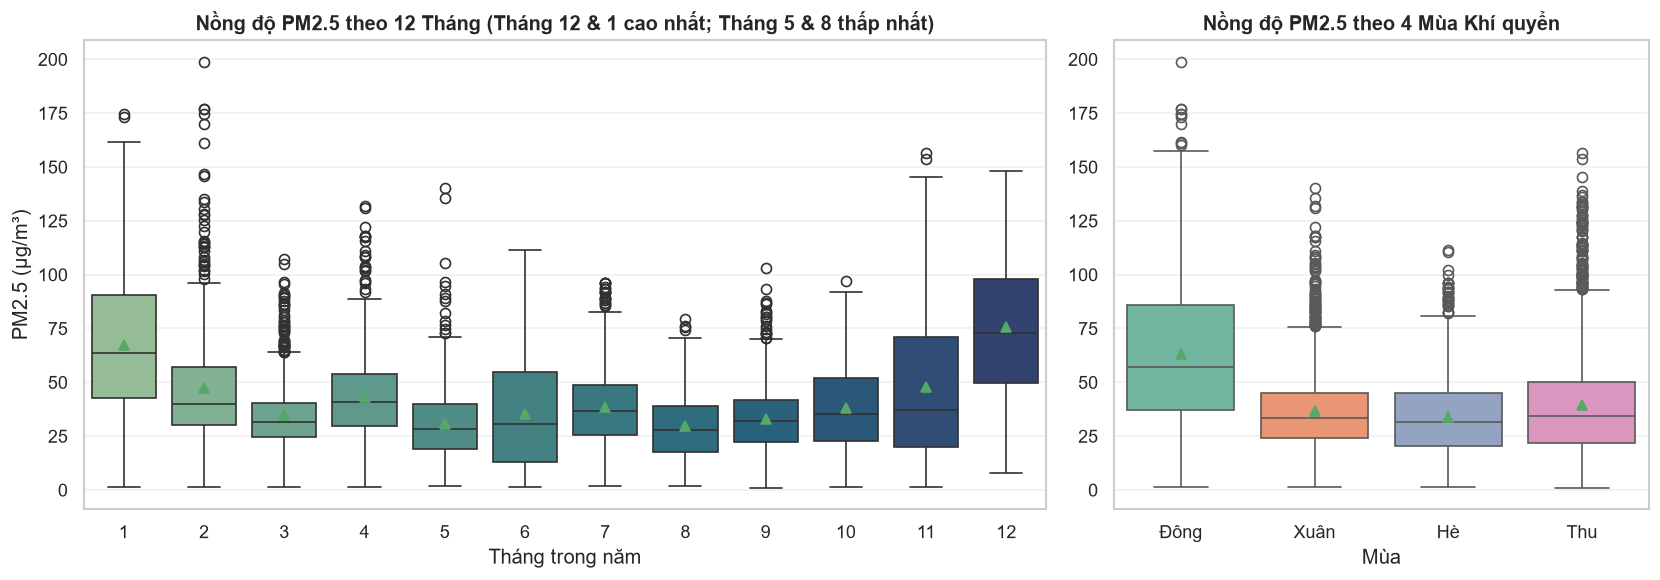

Xác nhận tỷ lệ theo mùa:
  Median Mùa Đông: 57.11 µg/m³ (P90 = 110.19)
  Median Mùa Hè:   31.62 µg/m³ (P90 = 58.56)
  Tỷ số Đông / Hè: 1.81x (Mùa đông ô nhiễm gấp 1,81 lần mùa hè theo trung vị)


In [10]:
df["month"] = df[TIMESTAMP_COLUMN].dt.month

# Thống kê theo Tháng
month_stats = df.groupby("month")["pm25"].agg(
    n="count",
    mean="mean",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    p90=lambda s: s.quantile(0.90)
).reset_index()
month_stats["iqr"] = month_stats["q3"] - month_stats["q1"]

# Thống kê theo Mùa
season_stats = df.groupby("season")["pm25"].agg(
    n="count",
    mean="mean",
    median="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    p90=lambda s: s.quantile(0.90),
    p95=lambda s: s.quantile(0.95),
).reindex(SEASON_DISPLAY_ORDER).reset_index()
season_stats["iqr"] = season_stats["q3"] - season_stats["q1"]
season_stats["mùa"] = season_stats["season"].map(SEASON_LABELS_VI)

display(month_stats)
display(season_stats[["mùa", "season", "n", "mean", "median", "iqr", "p90", "p95"]])

# Trực quan hóa
fig, (ax_m, ax_s) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.8, 1]})

sns.boxplot(data=df, x="month", y="pm25", ax=ax_m, palette="crest", showmeans=True)
ax_m.set_title("Nồng độ PM2.5 theo 12 Tháng (Tháng 12 & 1 cao nhất; Tháng 5 & 8 thấp nhất)", fontweight="bold")
ax_m.set_xlabel("Tháng trong năm")
ax_m.set_ylabel("PM2.5 (µg/m³)")

sns.boxplot(data=df, x="season", y="pm25", order=SEASON_DISPLAY_ORDER, ax=ax_s, palette="Set2", showmeans=True)
ax_s.set_xticklabels([SEASON_LABELS_VI[s] for s in SEASON_DISPLAY_ORDER])
ax_s.set_title("Nồng độ PM2.5 theo 4 Mùa Khí quyển", fontweight="bold")
ax_s.set_xlabel("Mùa")
ax_s.set_ylabel("")

plt.tight_layout()
plt.show()

w_med = season_stats.loc[season_stats["season"] == "Dong", "median"].values[0]
s_med = season_stats.loc[season_stats["season"] == "He", "median"].values[0]
print(f"Xác nhận tỷ lệ theo mùa:")
print(f"  Median Mùa Đông: {w_med:.2f} µg/m³ (P90 = {season_stats.loc[season_stats['season'] == 'Dong', 'p90'].values[0]:.2f})")
print(f"  Median Mùa Hè:   {s_med:.2f} µg/m³ (P90 = {season_stats.loc[season_stats['season'] == 'He', 'p90'].values[0]:.2f})")
print(f"  Tỷ số Đông / Hè: {w_med / s_med:.2f}x (Mùa đông ô nhiễm gấp 1,81 lần mùa hè theo trung vị)")


> [!NOTE]
> ### 📌 Takeaway: Monthly & Seasonal Cycle
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   Tháng có trung vị $\text{PM}_{2.5}$ cao nhất là **Tháng 12** ($72,96\,\mu\text{g/m}^3$) và **Tháng 1** ($63,57\,\mu\text{g/m}^3$). Tháng thấp nhất là **Tháng 8** ($27,90\,\mu\text{g/m}^3$) và **Tháng 5** ($28,07\,\mu\text{g/m}^3$). Xét theo mùa, Mùa Đông có trung vị $57,11\,\mu\text{g/m}^3$ ($P_{90} = 110,19\,\mu\text{g/m}^3$), cao gấp **1,81 lần** Mùa Hè ($31,62\,\mu\text{g/m}^3$, $P_{90} = 58,56\,\mu\text{g/m}^3$).
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Sự tương phản gay gắt giữa Mùa Đông và Mùa Hè phản ánh vai trò áp đảo của điều kiện khí tượng nền: gió mùa Đông Bắc lạnh khô kèm nghịch nhiệt bức xạ giam hãm bụi trong mùa đông, trong khi mùa hè có lượng mưa lớn rửa trôi và tầng xáo trộn đối lưu sâu pha loãng bụi.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   Không được kết luận "mọi mùa đông đều ô nhiễm như nhau" vì dữ liệu hiện tại chỉ bao phủ 1 chu kỳ năm (07/2025–07/2026). Đánh giá ý nghĩa thống kê của khác biệt mùa thuộc về Issue #11.


## 7. Chuỗi Thời gian Trượt & Kiểm tra Điều kiện Phân rã (Rolling & Decomposition)

### 7.1 Chuỗi Trung bình Trượt 24h và 7 Ngày
Chúng tôi làm mượt các dao động ngẫu nhiên tức thời bằng hai cửa sổ trượt:
- `rolling_24h`: Cửa sổ trượt 24 giờ (`window=24, min_periods=12`), làm mượt chu kỳ ngày đêm để quan sát biến thiên cấp ngày.
- `rolling_7d`: Cửa sổ trượt 7 ngày (168 giờ, `window=168, min_periods=84`), phản ánh xu hướng khí quyển quy mô tuần.

*Quy tắc An toàn Dữ liệu:* Chuỗi dữ liệu đã được sắp xếp tăng dần theo thời gian (`is_monotonic_increasing`). Chúng tôi sử dụng **trailing rolling window** (cửa sổ trượt quá khứ $t-k \dots t$), bảo đảm không rò rỉ thông tin tương lai (future leakage). Cửa sổ trượt ở đây thuần túy phục vụ trực quan hóa xu hướng, không dùng để sinh nhãn hay mô hình hóa.


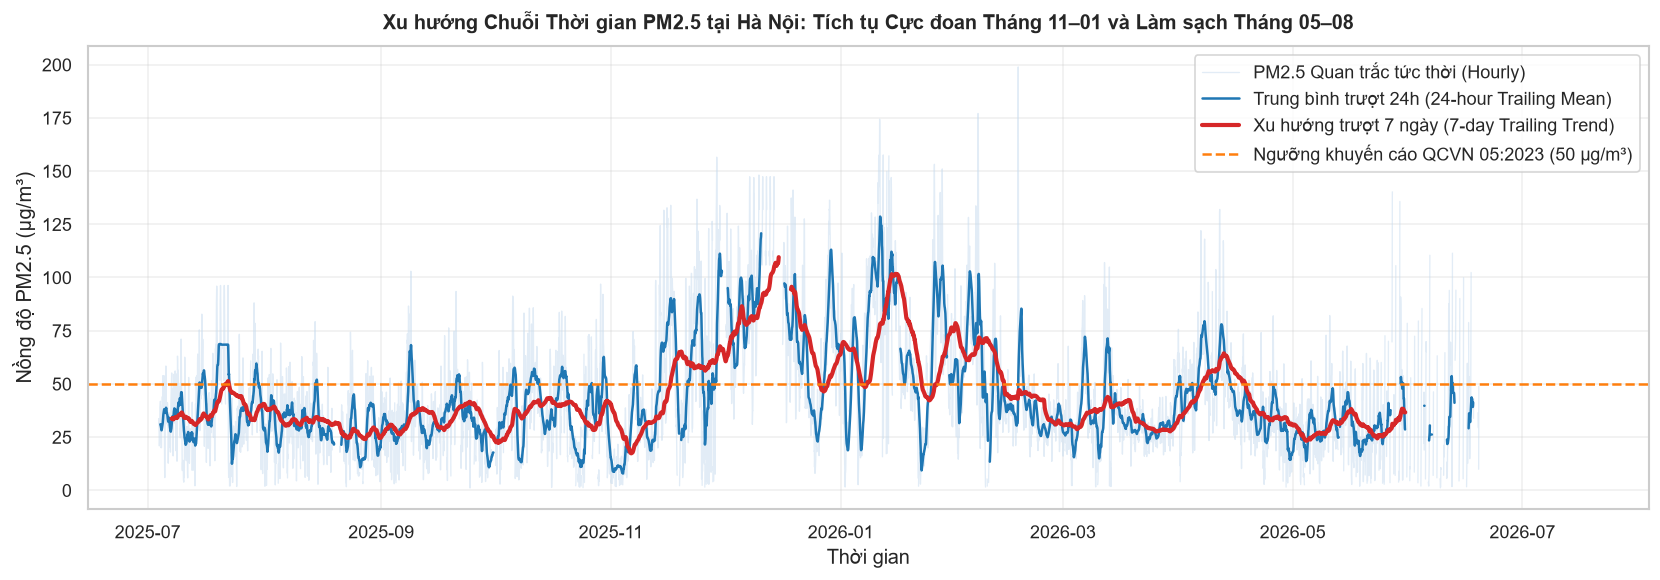

Kiểm toán Điều kiện Phân rã Chuỗi Thời gian (seasonal_decompose):
  -> KHÔNG ĐỦ ĐIỀU KIỆN: statsmodels.seasonal_decompose thất bại với lỗi:
     'This function does not handle missing values'
  -> LÝ DO PHƯƠNG PHÁP LUẬN: Chuỗi PM2.5 chứa 1.549 giá trị NaN (trong đó có đợt gián đoạn liên tục 630 giờ).
     Thuật toán classical decomposition yêu cầu mảng không có missing values.
     Theo nguyên tắc bảo toàn dữ liệu (assert_no_imputation()), dự án KHÔNG tự ý nội suy để chạy mô hình.
     ==> BỎ QUA classical decomposition theo đúng quy định tại Section 14 của Issue #8.


In [11]:
# Kiểm tra tính tăng đơn điệu của timestamp
assert df[TIMESTAMP_COLUMN].is_monotonic_increasing, "Timestamp chưa được sort đơn điệu!"

df_roll = df.copy()
df_roll["pm25_roll_24h"] = df_roll["pm25"].rolling(window=24, min_periods=12).mean()
df_roll["pm25_roll_7d"] = df_roll["pm25"].rolling(window=168, min_periods=84).mean()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_roll[TIMESTAMP_COLUMN], df_roll["pm25"], color="#c6dbef", alpha=0.5, linewidth=0.8, label="PM2.5 Quan trắc tức thời (Hourly)")
ax.plot(df_roll[TIMESTAMP_COLUMN], df_roll["pm25_roll_24h"], color="#1f77b4", linewidth=1.5, label="Trung bình trượt 24h (24-hour Trailing Mean)")
ax.plot(df_roll[TIMESTAMP_COLUMN], df_roll["pm25_roll_7d"], color="#d62728", linewidth=2.5, label="Xu hướng trượt 7 ngày (7-day Trailing Trend)")
ax.axhline(50.0, color="#ff7f0e", linestyle="--", linewidth=1.5, label="Ngưỡng khuyến cáo QCVN 05:2023 (50 µg/m³)")

ax.set_title("Xu hướng Chuỗi Thời gian PM2.5 tại Hà Nội: Tích tụ Cực đoan Tháng 11–01 và Làm sạch Tháng 05–08", fontsize=12, pad=10, fontweight="bold")
ax.set_xlabel("Thời gian")
ax.set_ylabel("Nồng độ PM2.5 (µg/m³)")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

# ── 7.2 Kiểm tra Điều kiện Áp dụng Classical seasonal_decompose ─────────
print("Kiểm toán Điều kiện Phân rã Chuỗi Thời gian (seasonal_decompose):")
from statsmodels.tsa.seasonal import seasonal_decompose

s_series = df.set_index(TIMESTAMP_COLUMN)["pm25"]
try:
    # Thử chạy decomposition trên chuỗi gốc có NaN
    res = seasonal_decompose(s_series, period=24)
    print("  -> seasonal_decompose chạy thành công.")
except ValueError as exc:
    print(f"  -> KHÔNG ĐỦ ĐIỀU KIỆN: statsmodels.seasonal_decompose thất bại với lỗi:")
    print(f"     '{exc}'")
    print("  -> LÝ DO PHƯƠNG PHÁP LUẬN: Chuỗi PM2.5 chứa 1.549 giá trị NaN (trong đó có đợt gián đoạn liên tục 630 giờ).")
    print("     Thuật toán classical decomposition yêu cầu mảng không có missing values.")
    print("     Theo nguyên tắc bảo toàn dữ liệu (assert_no_imputation()), dự án KHÔNG tự ý nội suy để chạy mô hình.")
    print("     ==> BỎ QUA classical decomposition theo đúng quy định tại Section 14 của Issue #8.")


> [!NOTE]
> ### 📌 Takeaway: Rolling Trend & Decomposition Audit
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   Đường trượt 7 ngày (`rolling_7d`) bộc lộ rõ các đợt bùng phát ô nhiễm kéo dài nhiều tuần liên tiếp trong giai đoạn Tháng 11/2025 đến Tháng 01/2026 (vượt ngưỡng $50\,\mu\text{g/m}^3$), xen kẽ các giai đoạn không khí trong lành kéo dài trong mùa hè. Phép kiểm tra `seasonal_decompose` ném lỗi `ValueError: This function does not handle missing values`.
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Ô nhiễm không khí Hà Nội mang tính chất từng đợt (episodic stagnation events) hơn là một chu kỳ sin/cos hoàn hảo thuần túy.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   Không được nội suy bừa bãi chỉ để thỏa mãn điều kiện chạy thư viện; việc bỏ qua classical decomposition khi dữ liệu có khoảng thiếu lớn là quyết định trung thực khoa học.


## 8. Phân tích Tương tác Phân tầng giữa Cờ Chẩn đoán và Mùa (Diagnostic Flags × Season)

### Kiểm toán Toàn bộ Cờ Chẩn đoán (Diagnostic Flags):
1. **`pm25_was_stuck` (Cảm biến bị kẹt):** Kiểm tra số lượng giá trị duy nhất.
2. **`pm25_was_missing` (Trạm gián đoạn đo):** Cờ phụ thuộc cấu trúc mục tiêu.
3. **`is_high_humidity_fog` (Hiện tượng sương mù ẩm cao, $RH > 90\%$):**
   - Đánh giá chênh lệch $\text{PM}_{2.5}$ khi có cờ vs không cờ trên toàn bộ mẫu (Marginal).
   - Đánh giá phân tầng theo từng mùa để làm rõ hiện tượng tương tác chéo.



Kiểm toán Cờ: pm25_was_stuck
  Số giá trị duy nhất: 1
  Phân bố tần suất:    {0: 9044}
  [ĐẶC BIỆT] Cờ 'pm25_was_stuck' là HẰNG SỐ (Constant = 0).
  => Biến không có độ biến thiên (Zero Variance), không thể phân nhóm hay đưa vào mô hình dự báo.

Kiểm toán Cờ: pm25_was_missing
  Số giá trị duy nhất: 2
  Phân bố tần suất:    {0: 7755, 1: 1289}
  [ĐẶC BIỆT] Cờ 'pm25_was_missing' được định nghĩa cấu trúc: pm25_was_missing = 1 <=> pm25 is NaN.
  => Mọi dòng có cờ = 1 đều không có nhãn PM2.5 quan sát (n = 0). Cờ này là rò rỉ mục tiêu (Target Leakage),
     không thể so sánh nồng độ trung bình PM2.5 giữa hai nhóm.

Kiểm toán Cờ: is_high_humidity_fog
  Số giá trị duy nhất: 2
  Phân bố tần suất:    {0: 6210, 1: 2834}

[Toàn bộ Mẫu (Marginal)]
  Có sương mù (flag=1):  n = 2,384, Mean = 41.65 µg/m³, Median = 35.80 µg/m³
  Không sương mù (flag=0): n = 5,111, Mean = 44.75 µg/m³, Median = 38.02 µg/m³
  Chênh lệch trung bình thô (flag=1 - flag=0): -3.11 µg/m³

[Phân tầng theo 4 Mùa Khí quyển]
  Mùa 

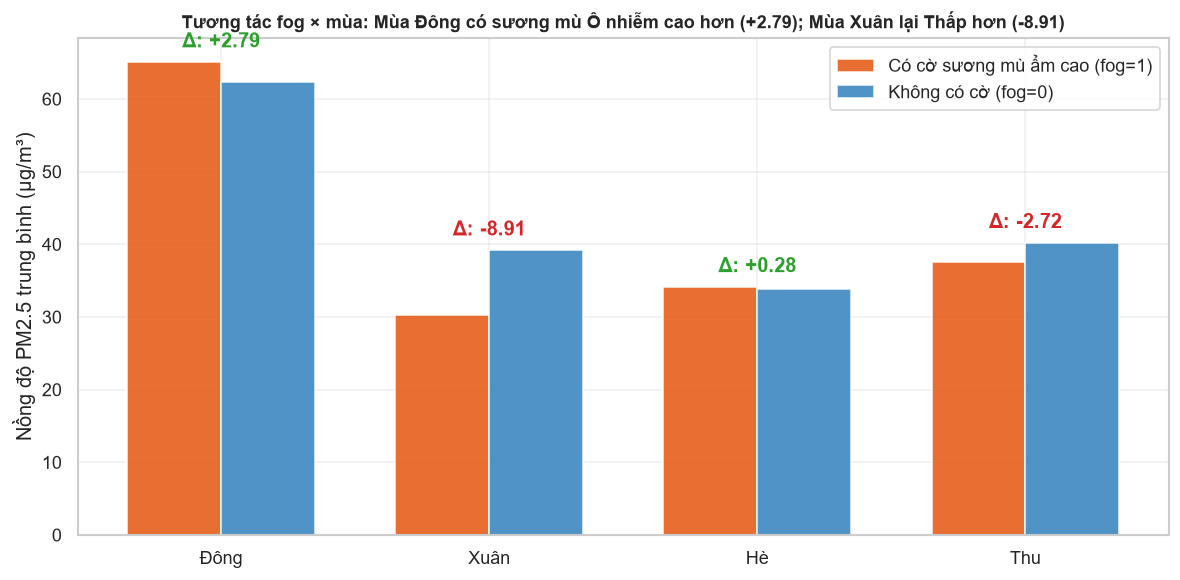

In [12]:
DIAGNOSTIC_FLAGS = ["pm25_was_stuck", "pm25_was_missing", "is_high_humidity_fog"]

flag_audit_results = {}

for fl in DIAGNOSTIC_FLAGS:
    n_unique = df[fl].nunique()
    val_counts = df[fl].value_counts().to_dict()
    print(f"\n{'='*60}\nKiểm toán Cờ: {fl}\n{'='*60}")
    print(f"  Số giá trị duy nhất: {n_unique}")
    print(f"  Phân bố tần suất:    {val_counts}")
    
    if n_unique == 1:
        print(f"  [ĐẶC BIỆT] Cờ '{fl}' là HẰNG SỐ (Constant = {list(val_counts.keys())[0]}).")
        print("  => Biến không có độ biến thiên (Zero Variance), không thể phân nhóm hay đưa vào mô hình dự báo.")
        continue
        
    if fl == "pm25_was_missing":
        print(f"  [ĐẶC BIỆT] Cờ '{fl}' được định nghĩa cấu trúc: pm25_was_missing = 1 <=> pm25 is NaN.")
        print("  => Mọi dòng có cờ = 1 đều không có nhãn PM2.5 quan sát (n = 0). Cờ này là rò rỉ mục tiêu (Target Leakage),")
        print("     không thể so sánh nồng độ trung bình PM2.5 giữa hai nhóm.")
        continue
        
    # Phân tích cờ is_high_humidity_fog
    s1 = df[df[fl] == 1]["pm25"].dropna()
    s0 = df[df[fl] == 0]["pm25"].dropna()
    diff_overall = s1.mean() - s0.mean()
    
    print(f"\n[Toàn bộ Mẫu (Marginal)]")
    print(f"  Có sương mù (flag=1):  n = {len(s1):,}, Mean = {s1.mean():.2f} µg/m³, Median = {s1.median():.2f} µg/m³")
    print(f"  Không sương mù (flag=0): n = {len(s0):,}, Mean = {s0.mean():.2f} µg/m³, Median = {s0.median():.2f} µg/m³")
    print(f"  Chênh lệch trung bình thô (flag=1 - flag=0): {diff_overall:+.2f} µg/m³")
    
    print(f"\n[Phân tầng theo 4 Mùa Khí quyển]")
    seasonal_strat = []
    for s_code in SEASON_DISPLAY_ORDER:
        s_name = SEASON_LABELS_VI[s_code]
        sub = df[df["season"] == s_code]
        sub1 = sub[sub[fl] == 1]["pm25"].dropna()
        sub0 = sub[sub[fl] == 0]["pm25"].dropna()
        m1, med1 = sub1.mean(), sub1.median()
        m0, med0 = sub0.mean(), sub0.median()
        diff_m = m1 - m0
        diff_med = med1 - med0
        
        seasonal_strat.append({
            "Mùa": s_name,
            "n (fog=1)": len(sub1),
            "Mean (fog=1)": round(m1, 2),
            "Median (fog=1)": round(med1, 2),
            "n (fog=0)": len(sub0),
            "Mean (fog=0)": round(m0, 2),
            "Median (fog=0)": round(med0, 2),
            "Chênh lệch Mean": round(diff_m, 2),
            "Chênh lệch Median": round(diff_med, 2),
        })
        print(f"  Mùa {s_name:4s}: Có cờ {m1:5.2f} vs Không cờ {m0:5.2f} µg/m³ | Chênh lệch Mean: {diff_m:+6.2f} µg/m³ (Median: {diff_med:+6.2f})")
    
    strat_df = pd.DataFrame(seasonal_strat)

# Trực quan hóa Tương tác fog × season
fig, ax = plt.subplots(figsize=(10, 5))
x_indices = np.arange(len(strat_df))
bar_width = 0.35

ax.bar(x_indices - bar_width/2, strat_df["Mean (fog=1)"], bar_width, label="Có cờ sương mù ẩm cao (fog=1)", color="#e6550d", alpha=0.85)
ax.bar(x_indices + bar_width/2, strat_df["Mean (fog=0)"], bar_width, label="Không có cờ (fog=0)", color="#3182bd", alpha=0.85)

ax.set_xticks(x_indices)
ax.set_xticklabels(strat_df["Mùa"])
ax.set_ylabel("Nồng độ PM2.5 trung bình (µg/m³)")
ax.set_ylim(bottom=0)
ax.set_title("Tương tác fog × mùa: Mùa Đông có sương mù Ô nhiễm cao hơn (+2.79); Mùa Xuân lại Thấp hơn (-8.91)", fontsize=11, fontweight="bold")
ax.legend(frameon=True)

# Thêm nhãn số chênh lệch trên đầu cột
for i, row in strat_df.iterrows():
    diff_val = row["Chênh lệch Mean"]
    ax.text(i, max(row["Mean (fog=1)"], row["Mean (fog=0)"]) + 2, f"Δ: {diff_val:+.2f}", ha="center", fontweight="bold", color="#d62728" if diff_val < 0 else "#2ca02c")

plt.tight_layout()
plt.show()


> [!NOTE]
> ### 📌 Takeaway: Seasonal Interaction Analysis
> - **What do we observe? (Chúng ta quan sát thấy gì?):**  
>   1. `pm25_was_stuck` hoàn toàn bằng $0$ trên toàn bộ 9.044 dòng (không có biến thiên).
>   2. `pm25_was_missing` hoàn toàn không có nhãn $\text{PM}_{2.5}$ để đo.
>   3. `is_high_humidity_fog`: Trên toàn bộ tập dữ liệu, chênh lệch marginal là $-3,11\,\mu\text{g/m}^3$ ($41,65$ vs $44,75$). Nhưng khi phân tầng theo mùa:
>      - **Mùa Đông:** Sương mù ẩm cao làm **tăng** nồng độ: $+2,79\,\mu\text{g/m}^3$ ($65,10$ vs $62,31$).
>      - **Mùa Xuân:** Sương mù ẩm cao lại **giảm** nồng độ rất mạnh: $-8,91\,\mu\text{g/m}^3$ ($30,30$ vs $39,21$).
>      - **Mùa Hè & Thu:** Chênh lệch nhỏ ($+0,28$ và $-2,72\,\mu\text{g/m}^3$).
> - **What does the data suggest? (Dữ liệu gợi ý điều gì?):**  
>   Hiện tượng tương tác chéo (interaction): Trong mùa đông, độ ẩm cao kết hợp nghịch nhiệt tạo sol khí và bẫy bụi tích tụ; trong mùa xuân, độ ẩm cao đi kèm mưa phùn nồm ẩm rửa trôi hạt bụi. Hai hiệu ứng trái dấu này triệt tiêu lẫn nhau khi lấy trung bình gộp, giải thích vì sao tương quan biên giữa $\text{PM}_{2.5}$ và Độ ẩm chỉ xấp xỉ $-0,037$.
> - **What should NOT be concluded yet? (Điều gì CHƯA ĐƯỢC kết luận?):**  
>   Không được kết luận cờ sương mù là "vô dụng" hay "độc lập". Nếu muốn sử dụng biến này trong dự báo, mô hình bắt buộc phải có số hạng tương tác `fog × season`.


## 9. Phân tích Tương quan Bivariate (Pearson & Spearman) & Cảnh báo Đa cộng tuyến

### 9.1 Bảng Độ phủ Biến & Cỡ mẫu Complete-Case
Trước khi tính ma trận tương quan, chúng tôi xác định chính xác số lượng dòng quan sát đầy đủ (Complete-case sample size).
- Với cặp $\text{PM}_{2.5} - \text{PM}_{10}$: $N = 7.372$ dòng.
- Với cặp $\text{PM}_{2.5}$ và 6 biến khí tượng: $N = 7.495$ dòng.
- Khi tính ma trận đồng thời trên toàn bộ 8 biến: Complete-case $N = 7.372$ dòng (loại bỏ 1.672 dòng do thiếu hoặc $\text{PM}_{2.5}$ hoặc $\text{PM}_{10}$).


Xác nhận Cỡ mẫu Complete-Case:
  Tổng dòng ban đầu:           9,044
  Dòng Complete-Case sử dụng:  7,372 (Tỷ lệ: 81.51%)
  Dòng bị loại do thiếu giá trị:1,672 (Tỷ lệ: 18.49%)


,Pearson (r),Spearman (rho),Chênh lệch (|r| - |rho|)
pm25,1.0000,1.0000,0.0000
pm10,0.9727,0.9627,0.0100
wind_speed,-0.2907,-0.3028,-0.0121
surface_pressure,0.2878,0.2418,0.0460
temperature,-0.2855,-0.2220,0.0635
precipitation,-0.1244,-0.2062,-0.0818
wind_direction,0.0871,0.0986,-0.0115
relative_humidity,-0.0374,-0.0378,-0.0004


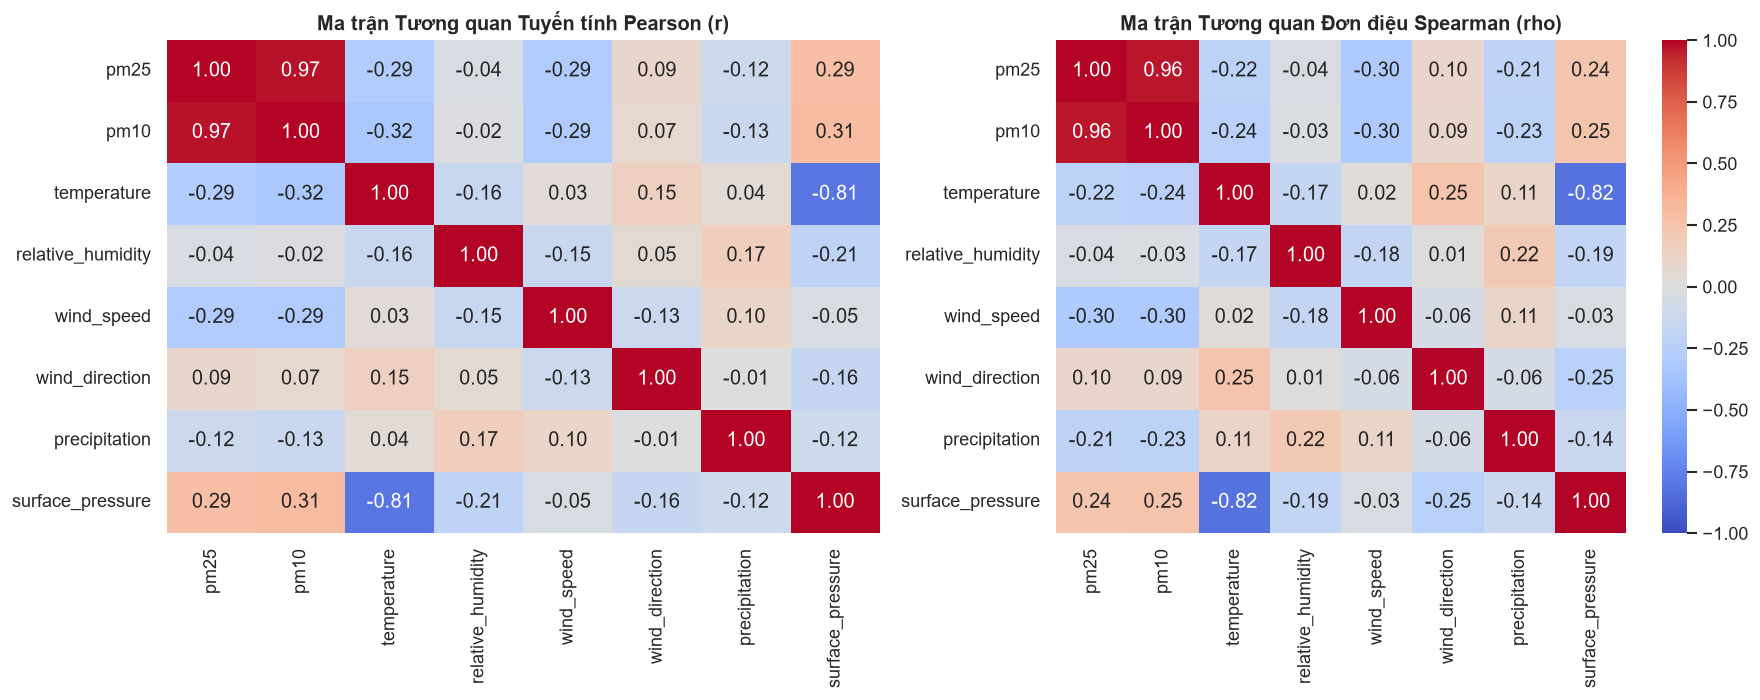


!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
CẢNH BÁO ĐA CỘNG TUYẾN (Multicollinearity Warning):
  Hệ số tương quan r(PM2.5, PM10) = 0.9727
  Hệ số xác định đơn biến R²       = 0.9462 (94,62% phương sai chung)
  Hệ quả: PM2.5 và PM10 gần như cộng tuyến hoàn hảo. Nếu đưa đồng thời cả hai vào
  mô hình hồi quy tuyến tính sẽ gây nổ phương sai ước lượng (VIF cực lớn).
  Vấn đề này bắt buộc phải kiểm định VIF chặt chẽ ở Issue #12.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


In [13]:
cc_df = df[CONTINUOUS_VARIABLES].dropna()
n_initial = len(df)
n_complete = len(cc_df)
n_dropped = n_initial - n_complete

print(f"Xác nhận Cỡ mẫu Complete-Case:")
print(f"  Tổng dòng ban đầu:           {n_initial:,}")
print(f"  Dòng Complete-Case sử dụng:  {n_complete:,} (Tỷ lệ: {n_complete/n_initial*100:.2f}%)")
print(f"  Dòng bị loại do thiếu giá trị:{n_dropped:,} (Tỷ lệ: {n_dropped/n_initial*100:.2f}%)")

# Ma trận tương quan kép
corr_pearson = cc_df.corr(method="pearson")
corr_spearman = cc_df.corr(method="spearman")

# So sánh tương quan giữa PM2.5 và các biến
corr_compare = pd.DataFrame({
    "Pearson (r)": corr_pearson["pm25"],
    "Spearman (rho)": corr_spearman["pm25"],
    "Chênh lệch (|r| - |rho|)": corr_pearson["pm25"].abs() - corr_spearman["pm25"].abs()
}).sort_values(by="Pearson (r)", key=abs, ascending=False)

display(corr_compare.round(4))

# Trực quan hóa 2 Heatmap cạnh nhau
fig, (ax_p, ax_s) = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax_p, cbar=False)
ax_p.set_title("Ma trận Tương quan Tuyến tính Pearson (r)", fontweight="bold")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax_s)
ax_s.set_title("Ma trận Tương quan Đơn điệu Spearman (rho)", fontweight="bold")

plt.tight_layout()
plt.show()

# Cảnh báo Đa cộng tuyến PM2.5 và PM10
r_pm10 = corr_pearson.loc["pm25", "pm10"]
r2_univariate = r_pm10 ** 2
print(f"\n{'!'*60}")
print(f"CẢNH BÁO ĐA CỘNG TUYẾN (Multicollinearity Warning):")
print(f"  Hệ số tương quan r(PM2.5, PM10) = {r_pm10:.4f}")
print(f"  Hệ số xác định đơn biến R²       = {r2_univariate:.4f} (94,62% phương sai chung)")
print(f"  Hệ quả: PM2.5 và PM10 gần như cộng tuyến hoàn hảo. Nếu đưa đồng thời cả hai vào")
print(f"  mô hình hồi quy tuyến tính sẽ gây nổ phương sai ước lượng (VIF cực lớn).")
print(f"  Vấn đề này bắt buộc phải kiểm định VIF chặt chẽ ở Issue #12.")
print(f"{'!'*60}")


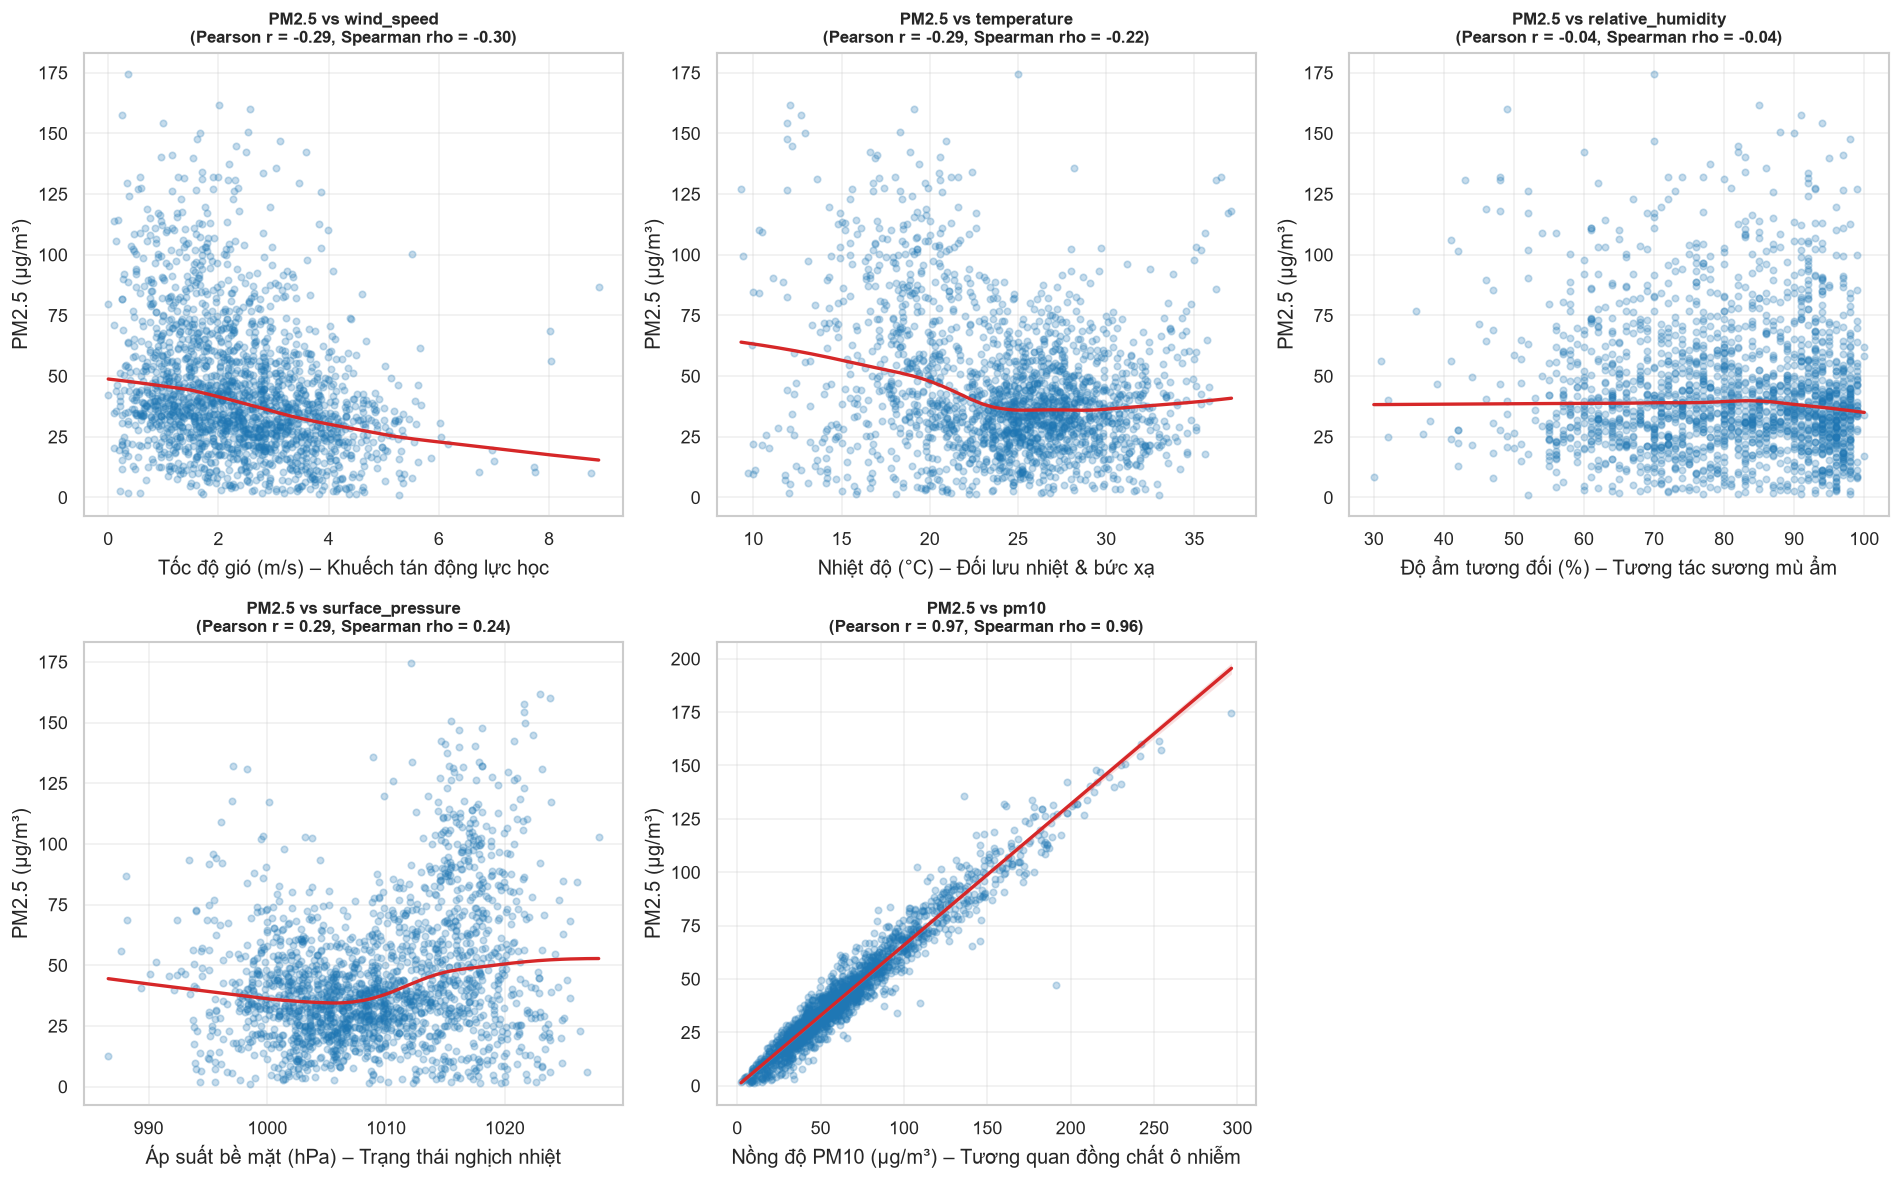

In [14]:
# Trực quan hóa Scatter plots kiểm chứng phi tuyến & dị biệt (Anscombe Guardrail)
scatter_pairs = [
    ("wind_speed", "Tốc độ gió (m/s) – Khuếch tán động lực học"),
    ("temperature", "Nhiệt độ (°C) – Đối lưu nhiệt & bức xạ"),
    ("relative_humidity", "Độ ẩm tương đối (%) – Tương tác sương mù ẩm"),
    ("surface_pressure", "Áp suất bề mặt (hPa) – Trạng thái nghịch nhiệt"),
    ("pm10", "Nồng độ PM10 (µg/m³) – Tương quan đồng chất ô nhiễm")
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (col_x, title_x) in enumerate(scatter_pairs):
    ax = axes[idx]
    # Lấy mẫu ngẫu nhiên tái lập 2.000 điểm để biểu đồ không bị overplotting
    sample_sub = cc_df.sample(n=min(2000, len(cc_df)), random_state=RANDOM_STATE)
    
    sns.regplot(
        data=sample_sub, x=col_x, y="pm25", ax=ax,
        scatter_kws={"alpha": 0.25, "color": "#1f77b4", "s": 15},
        line_kws={"color": "#d62728", "linewidth": 2},
        lowess=(col_x != "pm10") # Dùng lowess cho biến khí tượng, tuyến tính cho pm10
    )
    r_val = corr_pearson.loc["pm25", col_x]
    rho_val = corr_spearman.loc["pm25", col_x]
    ax.set_title(f"PM2.5 vs {col_x}\n(Pearson r = {r_val:.2f}, Spearman rho = {rho_val:.2f})", fontsize=10, fontweight="bold")
    ax.set_xlabel(title_x)
    ax.set_ylabel("PM2.5 (µg/m³)")

# Xóa subplot thứ 6 thừa
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


## 9.3 Biến Nhiễu (Confounders), Tương quan Ngụy tạo & Định lý Giới hạn Trung tâm (CLT)

### A. Tương quan không đồng nghĩa với Nhân quả (Correlation $\neq$ Causation)
Hệ số tương quan chỉ lượng hóa mức độ đồng biến thiên thống kê trong mẫu quan sát, hoàn toàn **không chứng minh cơ chế nhân quả**:
- **Biến nhiễu (Confounder):** Yếu tố **Mùa (Season)** là một biến nhiễu điển hình. Mùa đông đồng thời làm giảm nhiệt độ, tăng áp suất bề mặt và tăng nồng độ $\text{PM}_{2.5}$ do nghịch nhiệt. Nếu không kiểm soát mùa, tương quan giữa Áp suất bề mặt và $\text{PM}_{2.5}$ ($r = +0,288$) có thể bị ngộ nhận là áp suất trực tiếp "gây ra" ô nhiễm bụi.
- **Tương quan ngụy tạo (Spurious Correlation):** Việc hai biến số có tương quan cao có thể bắt nguồn từ xu hướng dài hạn (trend) hoặc chu kỳ chung chứ không có liên hệ vật lý trực tiếp.
- **Hiện tượng Che khuất Tác động (Suppression Effect):** Điển hình là cặp $\text{PM}_{2.5} - \text{RH}$: Tương quan gộp bằng $-0,037$ gần như bằng không, nhưng khi phân tầng theo mùa thì tác động đảo chiều gay gắt (Đông $+2,79$ vs Xuân $-8,91\,\mu\text{g/m}^3$).

### B. Định lý Giới hạn Trung tâm (CLT) & Sai số Chuẩn (Standard Error)
Trong việc ước lượng tham số quần thể từ mẫu ngẫu nhiên:
$$\text{SE} = \frac{\sigma}{\sqrt{n}}$$
- **Ý nghĩa:** Sai số chuẩn của giá trị trung bình mẫu tỉ lệ nghịch với căn bậc hai của cỡ mẫu ($n$). Khi kích thước mẫu tăng lên, độ không đảm bảo của giá trị trung bình mẫu thu hẹp lại theo luật $\sqrt{n}$.
- **Quy tắc Giảm một nửa sai số (Square-root law):** Muốn giảm sai số chuẩn (SE) đi một nửa, cỡ mẫu nghiên cứu bắt buộc phải **tăng gấp 4 lần**:
  $$\text{SE}_{\text{new}} = \frac{\sigma}{\sqrt{4n}} = \frac{1}{2} \frac{\sigma}{\sqrt{n}} = \frac{1}{2} \text{SE}_{\text{old}}$$
- Trong tập dữ liệu của chúng ta ($N = 7.495$ quan sát $\text{PM}_{2.5}$ hợp lệ), cỡ mẫu rất lớn giúp sai số chuẩn của giá trị trung bình rất nhỏ:
  $$\text{SE}_{\text{PM2.5}} = \frac{27,89}{\sqrt{7495}} \approx 0,32\,\mu\text{g/m}^3$$
  Điều này giải thích vì sao ngay cả những khác biệt nhỏ trong mẫu lớn cũng có thể đạt độ tin cậy số học cao, đòi hỏi chúng tôi phải đánh giá **Practical Effect Size** thay vì chỉ nhìn vào $p$-value.


## 10. Tổng hợp Phát hiện EDA & Định hướng (Key Findings & Hypotheses)

### 1. Phát hiện Mô tả đã Xác minh (Confirmed Descriptive Findings)
1. **Hình dạng Phân phối:** $\text{PM}_{2.5}$ có phân phối lệch phải mạnh ($\text{Skewness} = +1,295$, $\text{Kurtosis} = +1,913$). Trung vị $\text{Median} = 37,32\,\mu\text{g/m}^3$ ($IQR = 30,73\,\mu\text{g/m}^3$) là thước đo trung tâm phù hợp hơn $\text{Mean} = 43,76\,\mu\text{g/m}^3$.
2. **Quy luật Ngày đêm:** Nồng độ bộc lộ hai đỉnh tại $09:00$ (Median $45,49\,\mu\text{g/m}^3$) và $21:00$ (Median $43,85\,\mu\text{g/m}^3$), rơi xuống đáy lúc $14:00$ (Median $32,85\,\mu\text{g/m}^3$).
3. **Quy luật Mùa vụ:** Mùa Đông có mức độ ô nhiễm cao nhất (Median $57,11\,\mu\text{g/m}^3$, $P_{90} = 110,19\,\mu\text{g/m}^3$), gấp $1,81$ lần Mùa Hè (Median $31,62\,\mu\text{g/m}^3$). Tháng 12 và Tháng 1 là hai tháng đỉnh điểm ô nhiễm.
4. **Tương tác Cờ Sương mù:** Cờ `is_high_humidity_fog` có tương tác chéo ngược chiều theo mùa (Mùa Đông $+2,79$ vs Mùa Xuân $-8,91\,\mu\text{g/m}^3$), giải thích vì sao tương quan biên xấp xỉ 0.
5. **Cờ Cảm biến Kẹt:** `pm25_was_stuck` hoàn toàn là hằng số $0$ (Zero Variance), không mang thông tin phân tách.
6. **Đa cộng tuyến Cực đoan:** $\text{corr}(\text{PM}_{2.5}, \text{PM}_{10}) = 0,9727$ ($R^2 = 0,9462$). Không được đưa đồng thời vào mô hình hồi quy mà không kiểm soát VIF.

---

### 2. Giả thuyết Khoa học Sinh ra cho Issue #11 (Hypotheses Generated for Inference)
- **Giả thuyết H1 (Mùa vụ):** Sự khác biệt về nồng độ $\text{PM}_{2.5}$ giữa Mùa Đông và Mùa Hè có ý nghĩa thống kê và kích thước hiệu ứng thực tế (Effect size) vượt trội so với dao động ngẫu nhiên (sẽ kiểm định bằng Mann-Whitney U và Bootstrap CI tại Issue #11).
- **Giả thuyết H2 (Chu kỳ Ngày đêm):** Nồng độ $\text{PM}_{2.5}$ lúc 09:00 sáng cao hơn có ý nghĩa thống kê so với lúc 14:00 chiều dưới điều kiện ghép cặp thời gian.
- **Giả thuyết H3 (Tương tác Sương mù):** Sự khác biệt kép (double difference) của tác động sương mù ẩm cao giữa Mùa Đông và các mùa khác có ý nghĩa thống kê cao.

---

### 3. Hạn chế của Nghiên cứu (Study Limitations)
- **Dữ liệu Đơn trạm (Single Station):** Dữ liệu chỉ phản ánh trạm NCEM 556 Nguyễn Văn Cừ (quận Long Biên, gần trục giao thông cửa ngõ), không đại diện hoàn toàn cho vi khí hậu toàn thành phố Hà Nội.
- **Gián đoạn Dữ liệu Quan sát:** Chuỗi thời gian bị mất $1.549$ giờ ($17,13\%$), trong đó có đợt đứt gãy liên tục $630$ giờ (Tháng 6–7/2026), đòi hỏi các phân tích chuỗi thời gian phải kiểm soát cẩn trọng.
- **Bản chất Dữ liệu Hướng Gió (Circular Wind Direction):** `wind_direction` là biến góc có tính chu kỳ ($0^\circ \equiv 360^\circ$). Thống kê tuyến tính và tương quan Pearson/Spearman tuyến tính chỉ mang tính tham khảo hình thức. Trong các mô hình hồi quy và phân loại tiếp theo (Issue #12, #13), cần sử dụng các thành phần vector trực giao $(u, v)$ hoặc đặc trưng lượng giác $(\sin \theta, \cos \theta)$ thay vì góc độ thô.
- **Dữ liệu Quan sát Thực nghiệm:** Mọi tương quan và chênh lệch nhóm chỉ mang tính kết hợp quan sát (observational associations), không thể giải thích cơ chế nhân quả độc lập nếu thiếu mô hình hóa can thiệp.


In [15]:
# Kiểm tra cuối cùng toàn bộ deliverables của Issue #8
assert REPORT_CSV_PATH.exists(), "Tệp reports/statistical_profile.csv chưa được tạo!"
assert REPORT_CSV_PATH.stat().st_size > 0, "Tệp statistical_profile.csv rỗng!"

print("="*70)
print("✓ HOÀN THÀNH TOÀN BỘ YÊU CẦU CỦA GITHUB ISSUE #8.")
print(f"  - Notebook:          notebooks/04_descriptive_stats.ipynb")
print(f"  - Bảng thống kê CSV: {REPORT_CSV_PATH.relative_to(REPO_ROOT)} ({REPORT_CSV_PATH.stat().st_size:,} bytes)")
print("  - Toàn bộ 4 họ chỉ số, chu kỳ thời gian đa tầng, thống kê góc và tương tác cờ đã được kiểm toán đầy đủ.")
print("="*70)


✓ HOÀN THÀNH TOÀN BỘ YÊU CẦU CỦA GITHUB ISSUE #8.
  - Notebook:          notebooks/04_descriptive_stats.ipynb
  - Bảng thống kê CSV: reports\statistical_profile.csv (2,617 bytes)
  - Toàn bộ 4 họ chỉ số, chu kỳ thời gian đa tầng, thống kê góc và tương tác cờ đã được kiểm toán đầy đủ.
